<a href="https://colab.research.google.com/github/Lucas-O-S/N1_IA_VisaoComputacional/blob/main/CNN_Malaria_Grupo_executado.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Classificação de células com malária usando CNN: 5 classes × 2 classes
**Conjunto de dados:** *Malaria dataset (thin blood smear, updated)*, a versão do conjunto do NIH **revisada e reclassificada** no IEEE DataPort.

**Grupo:**  

            Adriana Kaori Kakazu
            
            Beatriz Buglio dos Santos

            Lucas Oliveira Silva

            Vitória Kaori Kuriyama



**O que este notebook faz**
- **Parte A:** classificar as **5 classes** da versão revisada (*Parasitized, Uninfected, Bad segmentation, Unsure, Weird*).
- **Parte B:** classificar **só *Parasitized* × *Uninfected*** (2 classes).
- **Parte C:** **comparar** os dois modelos.

As duas partes usam **a mesma CNN construída pelo grupo**, a mesma divisão por lâmina e os mesmos experimentos, para que a comparação seja justa.

**Roteiro**
0. Contexto: a malária e o que aparece nas lâminas
1. Configuração e semente fixa
2. Dados: obtenção e descrição das 5 classes
3. Análise exploratória
4. Pré-processamento e divisão sem vazamento
5. Arquitetura da CNN (com a teoria de cada camada)
6. Experimentos: funções comuns às duas partes
7. **Parte A** (5 classes): experimentos, avaliação, erros e Grad-CAM
8. **Parte B** (2 classes): experimentos, avaliação, erros e Grad-CAM
9. **Parte C**: comparação
10. Conclusão
11. Log de uso de IA

> **Versão executada:** contém as saídas reais de uma execução completa (CPU, 16 treinos) com o `malaria_thin_smear.zip` do IEEE. Dado que a versão do Kaggle apresentava classificações erroneas das lâminas.

## 0. Contexto: a malária e o que aparece nas lâminas

###  A doença
A **malária** é causada por protozoários do gênero ***Plasmodium***, transmitidos pela picada da fêmea do mosquito ***Anopheles***. O ***P. falciparum*** causa as formas mais graves e é a espécie das lâminas deste conjunto.

###  Ciclo de vida no ser humano
1. O mosquito injeta **esporozoítos**, que vão para o **fígado** e se multiplicam (fase sem sintomas).
2. O fígado libera **merozoítos**, que invadem as **hemácias** (ciclo eritrocítico, o que vemos na lâmina):
   - **Anel (trofozoíto jovem):** ponto de cromatina com um aro fino de citoplasma.
   - **Trofozoíto maduro:** o parasita cresce e acumula pigmento (hemozoína).
   - **Esquizonte:** o núcleo se divide em vários merozoítos; a hemácia **rompe** e libera novos merozoítos (picos de **febre**).
3. Alguns parasitas viram **gametócitos** (no *P. falciparum*, em forma de **banana/crescente**), que o mosquito ingere.

###  Quais fases aparecem nestas imagens?
No *P. falciparum*, as hemácias com formas maduras **grudam na parede dos capilares** (sequestro) e quase não circulam. No sangue periférico aparecem principalmente **anéis**, muitas vezes **colados na borda da hemácia** (forma *accolé*), às vezes dois por célula, e ocasionalmente gametócitos.

###  A lâmina e a coloração de Giemsa
Esfregaço fino = uma camada única de células. Na coloração de Giemsa, a **hemácia fica rosa/lilás** e a **cromatina do parasita roxo-avermelhada**. A cor é a principal pista; por isso usamos imagens RGB.

## 1. Configuração e semente fixa

### 📘 Por que fixar a semente?
Treinar uma rede envolve **sorteios**: inicialização dos pesos, ordem das imagens, divisão dos dados, data augmentation. Com a **semente fixa** (`SEED = 42`), os sorteios se repetem e o notebook dá **o mesmo resultado** a cada execução (reprodutibilidade). Na GPU podem sobrar diferenças mínimas.

### 📘 Por que 64×64?
As imagens têm ~130×130 px. Em 64×64 são **4× menos pixels**: menos memória e treino mais rápido no Colab, e o parasita continua visível.

In [ ]:
# --- Bibliotecas ---
import os, glob, re, time, hashlib, zipfile, shutil   # arquivos, tempo e hash
import numpy as np                  # vetores/matrizes (as imagens viram arrays numpy)
import pandas as pd                 # tabelas (DataFrame)
import matplotlib.pyplot as plt     # gráficos
from PIL import Image               # abrir e redimensionar imagens
from tqdm.auto import tqdm          # barra de progresso

import tensorflow as tf             # framework de deep learning
import keras                        # API de alto nível para montar redes
from keras import layers            # camadas: Conv2D, MaxPooling2D, Dense...

from sklearn.model_selection import StratifiedGroupKFold          # divisão por grupos (lâminas)
from sklearn.utils.class_weight import compute_class_weight       # pesos para classes raras
from sklearn.metrics import (confusion_matrix, ConfusionMatrixDisplay, classification_report,
                             accuracy_score, f1_score)

# --- Reprodutibilidade ---
SEED = 42
os.environ['PYTHONHASHSEED'] = str(SEED)
keras.utils.set_random_seed(SEED)   # fixa random, numpy e tensorflow de uma vez

# --- Hiperparâmetros gerais ---
IMG_SIZE = 64      # imagens redimensionadas para 64x64
BATCH    = 64      # imagens por lote (a cada lote os pesos são atualizados)
EPOCHS   = 15      # máximo de épocas por experimento (igual para todos)

# As 5 classes da versão revisada. As duas primeiras formam a Parte B.
CLASSES5 = ['Uninfected', 'Parasitized', 'Bad segmentation', 'Unsure', 'Weird']
CLASSES2 = ['Uninfected', 'Parasitized']
RODAR_TRANSFER = False   # comparação com MobileNetV2 pré-treinada (opcional, só referência)

FIG_DIR = 'figs'                     # figuras e tabelas salvas aqui (para os slides)
os.makedirs(FIG_DIR, exist_ok=True)
def salvar(nome):
    plt.savefig(os.path.join(FIG_DIR, nome), dpi=150, bbox_inches='tight')

print('TensorFlow', tf.__version__, '| Keras', keras.__version__)
print('GPU:', tf.config.list_physical_devices('GPU') or 'nenhuma (rodando na CPU)')

I0000 00:00:1793755769.326779    1569 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1793755769.369833    1569 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI AVX512_BF16 AVX512_FP16 AVX_VNNI AMX_TILE AMX_INT8 AMX_BF16 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


I0000 00:00:1793755770.527260    1569 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


TensorFlow 2.21.0 | Keras 3.15.1
GPU: nenhuma (rodando na CPU)


## 2. Dados: obtenção e descrição das classes

### 🔧 Como obter os dados
A versão revisada fica no **IEEE DataPort** e o download exige login (conta IEEE gratuita), então não dá para baixar automaticamente:
1. Baixe `malaria_thin_smear.zip` em <https://ieee-dataport.org/open-access/malaria-dataset-thin-blood-smear-updated>.
2. Coloque o zip no seu **Google Drive** (ex.: `MyDrive/malaria_thin_smear.zip`).
3. A célula abaixo monta o Drive e extrai o zip.


In [ ]:
ZIP_PATH = '/content/drive/MyDrive/malaria_thin_smear.zip'   # caminho do zip no Drive
DATA_DIR_MANUAL = '/home/claude/ieee/data'                                       # ou uma pasta já extraída

if DATA_DIR_MANUAL:
    DATA_DIR = DATA_DIR_MANUAL
else:
    try:
        from google.colab import drive
        drive.mount('/content/drive')                       # pede autorização para acessar o Drive
    except Exception as e:
        print('Fora do Colab:', e)
    DATA_DIR = 'malaria_ieee'
    if not os.path.isdir(DATA_DIR):
        with zipfile.ZipFile(ZIP_PATH) as z:
            z.extractall(DATA_DIR)
print('Pasta dos dados:', DATA_DIR)

Pasta dos dados: /home/claude/ieee/data


### As 5 classes

| Classe | O que é | Rótulo |
|---|---|---|
| **Uninfected** | hemácia sem parasita | 0 |
| **Parasitized** | hemácia com parasita (anel roxo no interior ou na borda) | 1 |
| **Bad segmentation** | recorte ruim: célula cortada, fragmento, duas células juntas ou só parte da célula | 2 |
| **Unsure** | o revisor **não teve certeza** se há parasita (ex.: ponto roxo pequeno que pode ser parasita ou artefato) | 3 |
| **Weird** | aparência **atípica**: coloração muito intensa, células deformadas, formas fora do padrão | 4 |

Do ponto de vista clínico, só *Parasitized* × *Uninfected* importa. As outras três são, na prática, imagens de **qualidade duvidosa**. Um modelo de 5 classes pode servir para **sinalizar imagens que precisam de revisão humana**.

### 🔧 Montando a tabela de imagens
A classe é o nome da pasta. Ignoramos arquivos que não são `.png` (como `Thumbs.db`). A função `lamina()` pega o trecho do nome antes de `_IMG`, que identifica a lâmina/paciente.

In [ ]:
def lamina(nome):
    # parte do nome antes de '_IMG' = identificador da lâmina/paciente
    m = re.match(r'^(.*?)_IMG', nome)
    return (m.group(1) if m else nome).lower().replace('_', '')

registros = {}
for p in sorted(glob.glob(os.path.join(DATA_DIR, '**', '*.png'), recursive=True)):
    classe = os.path.basename(os.path.dirname(p))           # nome da pasta = classe
    if classe in CLASSES5:
        registros.setdefault(os.path.basename(p), (classe, p))  # 1 linha por nome de arquivo

df = pd.DataFrame([{'arquivo': p, 'nome': n, 'classe': c, 'label': CLASSES5.index(c), 'lamina': lamina(n)}
                   for n, (c, p) in registros.items()])
assert len(df) > 0, f'Nenhuma imagem encontrada em {DATA_DIR}'
print('Imagens:', len(df))
df.head()

Imagens:

 27557


,arquivo,nome,classe,label,lamina
0,/home/claude/ieee/data/Bad segmentation/C100P6...,C100P61ThinF_IMG_20150918_145042_cell_5.png,Bad segmentation,2,c100p61thinf
1,/home/claude/ieee/data/Bad segmentation/C101P6...,C101P62ThinF_IMG_20150918_151239_cell_69.png,Bad segmentation,2,c101p62thinf
2,/home/claude/ieee/data/Bad segmentation/C101P6...,C101P62ThinF_IMG_20150918_155731_cell_25.png,Bad segmentation,2,c101p62thinf
3,/home/claude/ieee/data/Bad segmentation/C101P6...,C101P62ThinF_IMG_20150923_165215_cell_20.png,Bad segmentation,2,c101p62thinf
4,/home/claude/ieee/data/Bad segmentation/C101P6...,C101P62ThinF_IMG_20150923_165215_cell_7.png,Bad segmentation,2,c101p62thinf


## 3. Análise exploratória (EDA)

### 📘 Para que serve
Descobrir antes de treinar os problemas que estragariam o modelo ou a avaliação: **desbalanceamento** (classes de tamanhos muito diferentes), **tamanhos variados**, **duplicatas** e **vieses** (características ligadas à classe sem relação com a doença, como a lâmina de origem).

### 📘 Por que o desbalanceamento importa
Se uma classe tem 50% das imagens e outra 0,8%, um modelo que **nunca** prevê a classe rara ainda acerta quase tudo. Por isso, com classes desbalanceadas, a **acurácia engana**, e usamos o **F1 macro** (a média simples do F1 de cada classe, em que todas as classes pesam igual).

,imagens,%
classe,,
Uninfected,14141,51.32
Parasitized,12057,43.75
Bad segmentation,571,2.07
Unsure,570,2.07
Weird,218,0.79


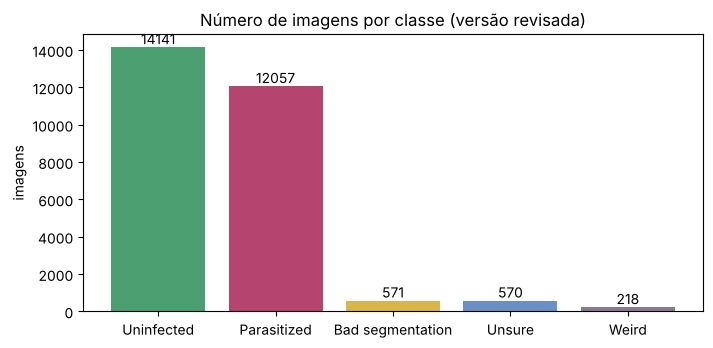

Razão maior/menor classe: 65 vezes


In [ ]:
contagem = df['classe'].value_counts().reindex(CLASSES5)
resumo = pd.DataFrame({'imagens': contagem, '%': (100 * contagem / contagem.sum()).round(2)})
display(resumo)

cores5 = ['#4C9F70', '#B5446E', '#D9B44A', '#6B8EC4', '#8A7A90']
plt.figure(figsize=(8, 3.6))
bars = plt.bar(contagem.index, contagem.values, color=cores5)
plt.bar_label(bars)
plt.title('Número de imagens por classe (versão revisada)'); plt.ylabel('imagens')
salvar('eda_distribuicao_classes.png'); plt.show()
print(f'Razão maior/menor classe: {contagem.max() / contagem.min():.0f} vezes')

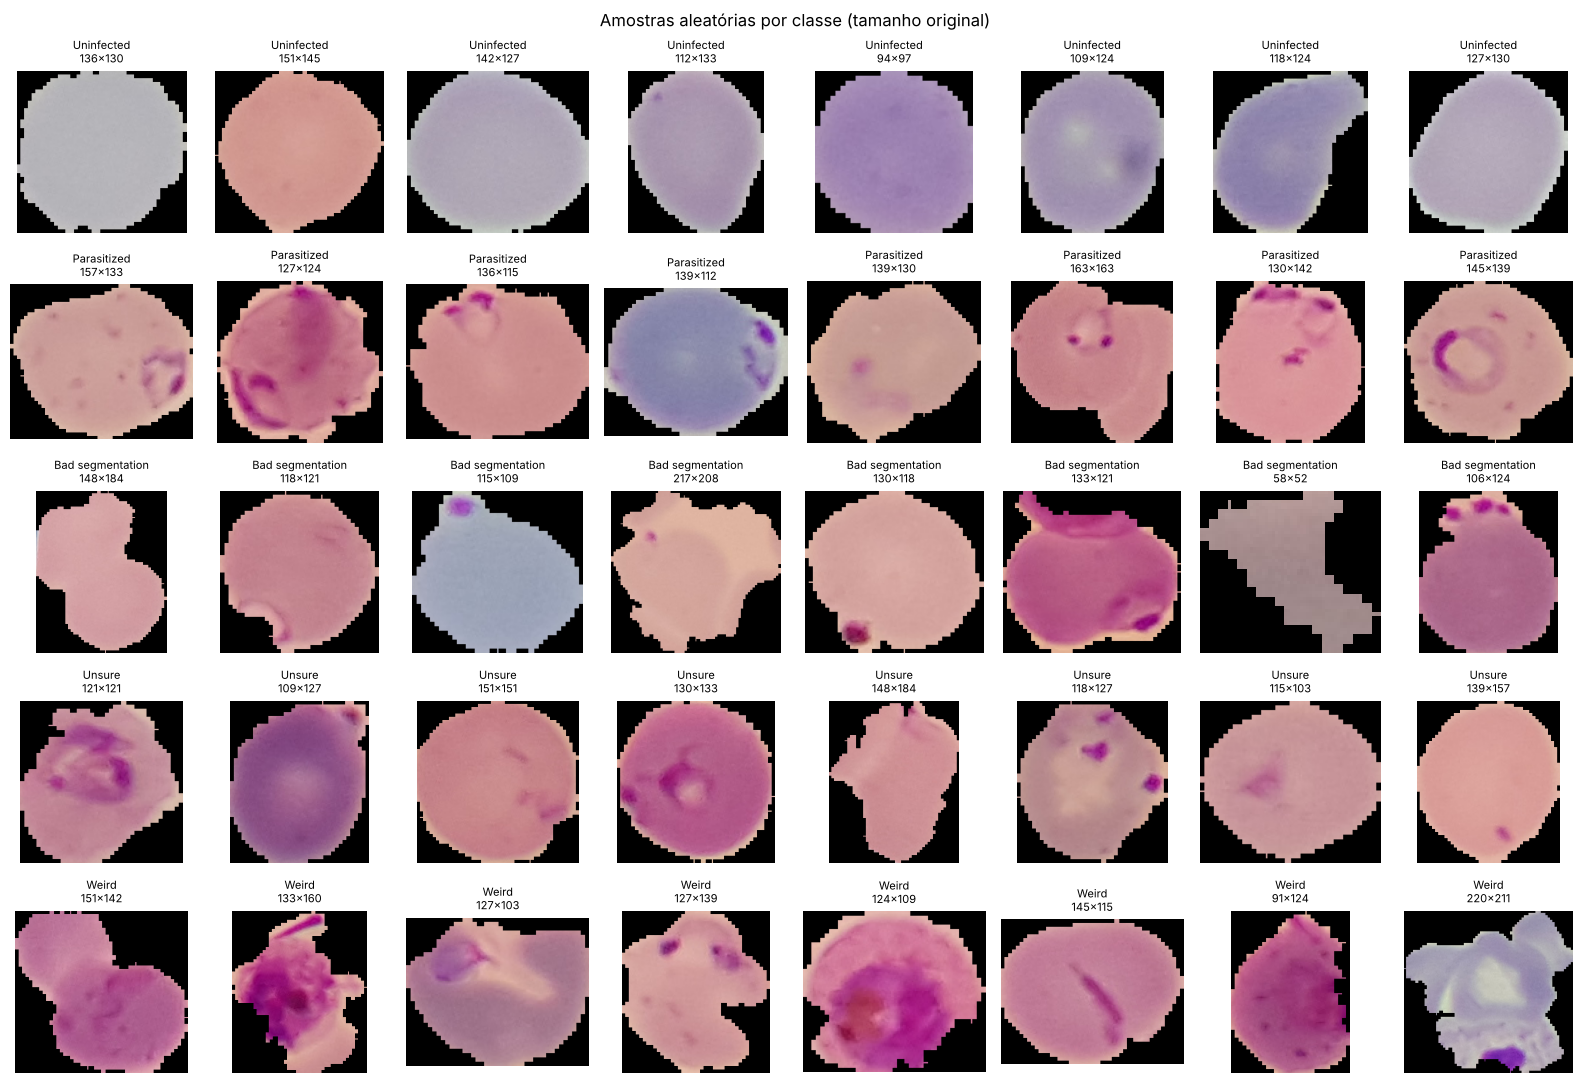

In [ ]:
# 8 imagens sorteadas de cada classe, no tamanho original
fig, axes = plt.subplots(5, 8, figsize=(16, 11))
for i, c in enumerate(CLASSES5):
    amostra = df[df.classe == c].sample(8, random_state=SEED)
    for j, (_, r) in enumerate(amostra.iterrows()):
        img = Image.open(r.arquivo)
        axes[i, j].imshow(img); axes[i, j].axis('off')
        axes[i, j].set_title(f'{c}\n{img.size[0]}x{img.size[1]}', fontsize=8)
plt.suptitle('Amostras aleatórias por classe (tamanho original)')
plt.tight_layout(); salvar('eda_amostras.png'); plt.show()

**O que observar:** em *Parasitized*, a mancha roxa do anel (no meio ou colada na borda). Em *Bad segmentation*, recortes irregulares e células incompletas. Em *Unsure*, pontos roxos pequenos e ambíguos. Em *Weird*, células com coloração intensa ou forma muito diferente. Repare que **as três classes novas se parecem bastante com *Parasitized***: muitas têm manchas roxas.

### 3.1 Resolução (tamanho original)

lendo tamanhos:   0%|          | 0/27557 [00:00<?, ?it/s]

,largura (mediana),altura (mediana),proporção (mediana),menor lado < 64px
classe,,,,
Uninfected,130.0,130.0,1.00,13
Parasitized,133.0,133.0,1.00,1
Bad segmentation,136.0,136.0,0.98,2
Unsure,130.0,130.0,1.00,1
Weird,121.0,118.0,1.00,3


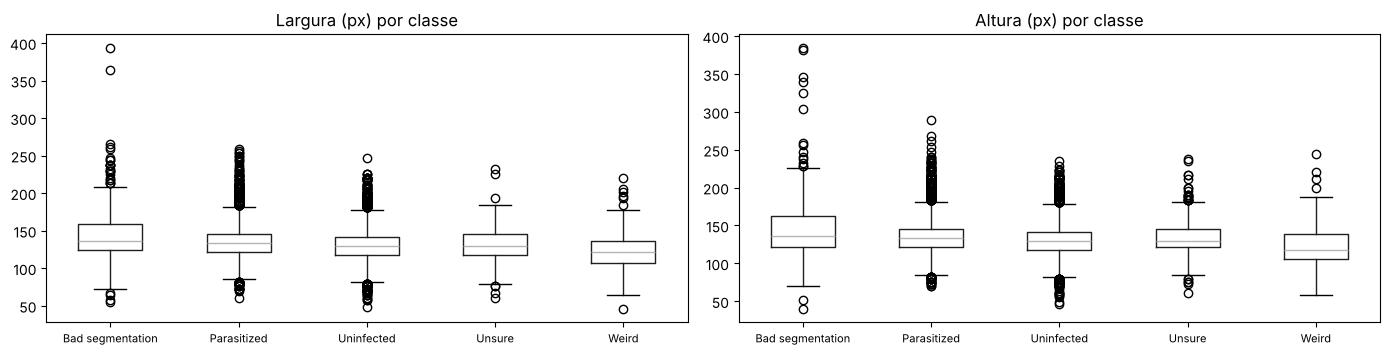

Geral: mediana 130 x 130 px | menor 46 x 40 | maior 394 x 385


In [ ]:
# Lemos só o cabeçalho de cada arquivo (rápido) e calculamos um hash MD5 para achar duplicatas.
larg, alt, hashes = [], [], []
for p in tqdm(df.arquivo, desc='lendo tamanhos'):
    with Image.open(p) as im:
        w, h = im.size
    larg.append(w); alt.append(h)
    with open(p, 'rb') as f:
        hashes.append(hashlib.md5(f.read()).hexdigest())
df['largura'], df['altura'], df['md5'] = larg, alt, hashes
df['proporcao'] = df.largura / df.altura      # 1,0 = imagem quadrada

res = df.groupby('classe')[['largura', 'altura', 'proporcao']].median().reindex(CLASSES5).round(2)
res['menor lado < 64px'] = df.assign(p=(df[['largura', 'altura']].min(axis=1) < IMG_SIZE)).groupby('classe').p.sum().reindex(CLASSES5)
res.columns = ['largura (mediana)', 'altura (mediana)', 'proporção (mediana)', 'menor lado < 64px']
display(res)

fig, ax = plt.subplots(1, 2, figsize=(14, 3.8))
df.boxplot(column='largura', by='classe', ax=ax[0], grid=False); ax[0].set_title('Largura (px) por classe')
df.boxplot(column='altura', by='classe', ax=ax[1], grid=False); ax[1].set_title('Altura (px) por classe')
for a in ax: a.set_xlabel(''); a.tick_params(axis='x', labelsize=8)
plt.suptitle(''); plt.tight_layout(); salvar('eda_resolucao.png'); plt.show()
print(f'Geral: mediana {df.largura.median():.0f} x {df.altura.median():.0f} px | '
      f'menor {df.largura.min()} x {df.altura.min()} | maior {df.largura.max()} x {df.altura.max()}')

### 3.2 Duplicatas e viés de lâmina

In [ ]:
# Duplicatas exatas (mesmo MD5 = mesmo conteúdo de arquivo)
dup = df[df.duplicated('md5', keep=False)]
print('Imagens com conteúdo duplicado:', len(dup))
antes = len(df)
df = df.drop_duplicates('md5').reset_index(drop=True)
print(f'Após remover duplicatas: {len(df)} imagens (removidas {antes - len(df)})')

# Em quantas lâminas aparece cada classe?
lam = df.groupby('classe').lamina.nunique().reindex(CLASSES5)
print('\nLâminas em que cada classe aparece:'); print(lam.to_string())
por_lamina = df.groupby('lamina').classe.nunique()
print('\nTotal de lâminas:', df.lamina.nunique())
so_unin = df.groupby('lamina').classe.agg(lambda s: set(s) == {'Uninfected'})
print('Lâminas só com Uninfected (pacientes saudáveis):', int(so_unin.sum()))

Imagens com conteúdo duplicado: 0
Após remover duplicatas: 27557 imagens (removidas 0)

Lâminas em que cada classe aparece:
classe
Uninfected          201
Parasitized         147
Bad segmentation     86
Unsure              106
Weird                58

Total de lâminas: 201
Lâminas só com Uninfected (pacientes saudáveis): 47


**Achados da análise exploratória** (do conjunto revisado; os números se repetem em qualquer execução)
- **Forte desbalanceamento:** *Uninfected* e *Parasitized* somam ~95% das imagens. *Bad segmentation* e *Unsure* têm ~2% cada, e *Weird* menos de 1%. Isso exige métricas por classe e F1 macro, e testamos **pesos de classe** como experimento.
- **Resolução variável** (mediana ~130 px), com células quase quadradas: redimensionamos para 64×64.
- **Viés de lâmina:** cerca de 200 lâminas, e as dos pacientes saudáveis só têm *Uninfected*. A divisão é **por lâmina**.

## 4. Pré-processamento e divisão sem vazamento

### 📘 Treino, validação e teste
| Conjunto | Para que serve | Quando é usado |
|---|---|---|
| **Treino** | a rede ajusta os pesos | todas as épocas |
| **Validação** | comparar experimentos e escolher o modelo | ao fim de cada época e na escolha |
| **Teste** | medir o desempenho final de forma honesta | **uma única vez**, no fim |

### 🔧 O que o código faz
- Converte cada imagem para RGB e redimensiona para 64×64 (bilinear). Guarda em `uint8`; a normalização para [0, 1] fica **dentro do modelo**.
- **`StratifiedGroupKFold`**: divide **por lâmina** (nenhuma lâmina em dois conjuntos), tentando manter a proporção das **5 classes**. Usamos 1 de 5 partes como teste (~20%), depois 1 de 5 do restante como validação (~16%).
- **A Parte B usa exatamente a mesma divisão**, só que sem as 3 classes novas. Assim o teste da Parte B é um **subconjunto** do teste da Parte A, e a comparação é justa.

In [ ]:
def carregar(p):
    # abre, garante RGB, redimensiona para 64x64 e converte em array numpy
    with Image.open(p) as im:
        return np.asarray(im.convert('RGB').resize((IMG_SIZE, IMG_SIZE), Image.BILINEAR), dtype=np.uint8)

cache = f'malaria_ieee_{IMG_SIZE}px.npz'          # evita redimensionar de novo
if os.path.exists(cache) and len(np.load(cache)['y']) == len(df):
    X = np.load(cache)['X']
else:
    X = np.stack([carregar(p) for p in tqdm(df.arquivo, desc='redimensionando')])
    np.savez_compressed(cache, X=X, y=df.label.values)
y5 = df.label.values           # rótulos 0..4
grupos = df.lamina.values
print('X:', X.shape, X.dtype, '| memória: %.0f MB' % (X.nbytes / 1e6))

redimensionando:   0%|          | 0/27557 [00:00<?, ?it/s]

X: (27557, 64, 64, 3) uint8 | memória: 339 MB


In [ ]:
# 1) TESTE = 1 de 5 partes, por lâmina, estratificado pelas 5 classes
sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
idx_resto, idx_test = next(sgkf.split(X, y5, grupos))
# 2) VALIDAÇÃO = 1 de 5 partes do restante
sgkf2 = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
i_tr, i_va = next(sgkf2.split(X[idx_resto], y5[idx_resto], grupos[idx_resto]))
idx_train, idx_val = idx_resto[i_tr], idx_resto[i_va]

# checagem de vazamento: nenhuma lâmina em comum
g_tr, g_va, g_te = set(grupos[idx_train]), set(grupos[idx_val]), set(grupos[idx_test])
assert not (g_tr & g_va) and not (g_tr & g_te) and not (g_va & g_te), 'Vazamento de lâmina!'

# Tabela: quantas imagens de cada classe em cada conjunto
split = pd.DataFrame({nome: pd.Series(y5[idx]).map(dict(enumerate(CLASSES5))).value_counts().reindex(CLASSES5).fillna(0).astype(int)
                      for nome, idx in [('treino', idx_train), ('validação', idx_val), ('teste', idx_test)]})
split.loc['TOTAL'] = split.sum()
split.loc['lâminas'] = [len(g_tr), len(g_va), len(g_te)]
split.to_csv(os.path.join(FIG_DIR, 'divisao.csv'))
split

,treino,validação,teste
Uninfected,9119,2192,2830
Parasitized,7693,1879,2485
Bad segmentation,366,96,109
Unsure,360,94,116
Weird,144,31,43
TOTAL,17682,4292,5583
lâminas,130,31,40


## 5. Arquitetura da CNN (construída camada por camada)

### 📘 Como uma CNN "enxerga" uma imagem
Uma imagem colorida 64×64 é um **tensor 64×64×3** (altura × largura × canais RGB).

- **Convolução (`Conv2D`):** um **filtro** 3×3 desliza pela imagem; em cada posição multiplica seus pesos pelos pixels e soma (mais um *bias*), gerando um **mapa de características**. Os pesos do filtro **são aprendidos no treino**: um filtro pode aprender a detectar "ponto roxo escuro". Com 16 filtros saem 16 mapas (64×64×16). `padding='same'` mantém o tamanho.
- **ReLU** (`max(0, x)`): zera os negativos; dá **não linearidade** à rede.
- **MaxPooling 2×2:** fica com o maior valor de cada quadrado 2×2, então o mapa cai **pela metade**. Mantém "tem algo aqui" e tolera pequenos deslocamentos.
- **Blocos empilhados:** os primeiros detectam coisas simples (bordas, manchas); os seguintes combinam em padrões complexos. O mapa fica menor (64→32→16→8) e com mais canais (16→32→64).
- **Flatten:** transforma 8×8×64 num vetor de 4.096 números.
- **Dense:** cada neurônio recebe todos os valores e os combina para decidir.
- **Saída softmax:** um neurônio **por classe**. A softmax transforma as saídas em **probabilidades que somam 1**; a classe prevista é a de maior probabilidade. (Com 2 classes, a softmax de 2 saídas equivale à sigmoid de 1 saída; usamos softmax nas duas partes para o código ser o mesmo.)

### 📘 Como a rede aprende
1. **Perda** `sparse_categorical_crossentropy`: mede o quanto a probabilidade da classe correta está longe de 1.
2. **Retropropagação:** calcula o **gradiente** (em que direção mudar cada peso para a perda cair).
3. **Otimizador Adam:** dá um passo nessa direção, do tamanho da **taxa de aprendizado** (0,001).
4. Repete para cada lote; ver o treino inteiro uma vez = **1 época**.

### 📘 Escolhas do baseline
| Escolha | Justificativa |
|---|---|
| Entrada 64×64×3 | mantém a cor (o parasita é roxo no Giemsa) e cabe no Colab |
| `Rescaling(1/255)` | pixels de 0–255 para 0–1 |
| Kernel 3×3, `same` | o anel do parasita é pequeno; kernel pequeno capta pontos e bordas |
| Filtros 16 → 32 → 64 | o mapa encolhe e ganha profundidade: padrões cada vez mais complexos |
| MaxPooling 2×2 | reduz o mapa pela metade e o número de parâmetros |
| ReLU | simples, não satura |
| Softmax + entropia cruzada | uma probabilidade por classe |
| Adam, lr = 1e-3 | otimizador padrão, robusto |

In [ ]:
# Configuração do baseline
BASE = dict(aug=False, dropout=0.0, bn=False, blocos=3, lr=1e-3, early_stopping=False, pesos_classe=False)
FILTROS = [16, 32, 64, 128]   # filtros de cada bloco (o 4º só com blocos=4)

def construir_cnn(cfg, n_classes, nome='cnn'):
    m = keras.Sequential(name=nome)
    m.add(keras.Input(shape=(IMG_SIZE, IMG_SIZE, 3)))       # imagem 64x64 RGB
    if cfg['aug']:   # data augmentation: só atua no treino
        m.add(layers.RandomFlip('horizontal_and_vertical', seed=SEED, name='aug_flip'))       # espelha
        m.add(layers.RandomRotation(0.5, fill_mode='constant', seed=SEED, name='aug_rot'))   # até ±180°
        m.add(layers.RandomZoom(0.1, fill_mode='constant', seed=SEED, name='aug_zoom'))     # zoom ±10%
    m.add(layers.Rescaling(1. / 255, name='rescale'))       # 0-255 -> 0-1
    for i in range(cfg['blocos']):                          # bloco: Conv -> (BN) -> ReLU -> MaxPool
        m.add(layers.Conv2D(FILTROS[i], 3, padding='same', use_bias=not cfg['bn'], name=f'conv{i+1}'))
        if cfg['bn']:
            m.add(layers.BatchNormalization(name=f'bn{i+1}'))
        m.add(layers.Activation('relu', name=f'relu{i+1}'))
        m.add(layers.MaxPooling2D(2, name=f'pool{i+1}'))    # metade da altura e da largura
    m.add(layers.Flatten(name='flatten'))                   # mapa 3D -> vetor
    m.add(layers.Dense(64, activation='relu', name='dense'))
    if cfg['dropout'] > 0:
        m.add(layers.Dropout(cfg['dropout'], name='dropout'))
    m.add(layers.Dense(n_classes, activation='softmax', name='saida'))   # 1 probabilidade por classe
    m.compile(optimizer=keras.optimizers.Adam(cfg['lr']),
              loss='sparse_categorical_crossentropy', metrics=['accuracy'])
    return m

for n in (5, 2):
    demo = construir_cnn(BASE, n, f'baseline_{n}_classes')
    tab = pd.DataFrame([{'camada': l.name, 'tipo': type(l).__name__, 'saída': tuple(l.output.shape[1:]),
                         'parâmetros': l.count_params()} for l in demo.layers])
    print(f'\n=== Baseline com {n} classes: {demo.count_params():,} parâmetros ==='.replace(',', '.'))
    display(tab)


=== Baseline com 5 classes: 286.117 parâmetros ===


,camada,tipo,saída,parâmetros
0,rescale,Rescaling,"(64, 64, 3)",0
1,conv1,Conv2D,"(64, 64, 16)",448
2,relu1,Activation,"(64, 64, 16)",0
3,pool1,MaxPooling2D,"(32, 32, 16)",0
4,conv2,Conv2D,"(32, 32, 32)",4640
5,relu2,Activation,"(32, 32, 32)",0
6,pool2,MaxPooling2D,"(16, 16, 32)",0
7,conv3,Conv2D,"(16, 16, 64)",18496
8,relu3,Activation,"(16, 16, 64)",0
9,pool3,MaxPooling2D,"(8, 8, 64)",0



=== Baseline com 2 classes: 285.922 parâmetros ===


,camada,tipo,saída,parâmetros
0,rescale,Rescaling,"(64, 64, 3)",0
1,conv1,Conv2D,"(64, 64, 16)",448
2,relu1,Activation,"(64, 64, 16)",0
3,pool1,MaxPooling2D,"(32, 32, 16)",0
4,conv2,Conv2D,"(32, 32, 32)",4640
5,relu2,Activation,"(32, 32, 32)",0
6,pool2,MaxPooling2D,"(16, 16, 32)",0
7,conv3,Conv2D,"(16, 16, 64)",18496
8,relu3,Activation,"(16, 16, 64)",0
9,pool3,MaxPooling2D,"(8, 8, 64)",0


### 📘 Calculando os parâmetros (pergunta comum na arguição)
- **Conv2D:** `(3 × 3 × canais de entrada + 1) × filtros` → conv1 = (27 + 1)·16 = **448**; conv2 = (144 + 1)·32 = **4.640**; conv3 = (288 + 1)·64 = **18.496**.
- **ReLU, MaxPooling, Flatten, Rescaling:** **0** parâmetros.
- **Dense 64:** (4.096 + 1)·64 = **262.208**, ou seja ~92% de tudo: o lugar mais sujeito a *overfitting*.
- **Saída:** (64 + 1)·n_classes → **325** com 5 classes, **130** com 2.
- **Total:** **286.117** (5 classes) e **285.922** (2 classes): as redes são idênticas, exceto a última camada.

## 6. Experimentos: funções comuns às duas partes

### 📘 Overfitting e as técnicas testadas
**Overfitting** = a rede **decora** o treino. Sinal: acurácia de treino subindo e a de validação parada ou caindo, com a **perda de validação subindo**. **Gap** = acurácia de treino − acurácia de validação.

| Exp. | Técnica | O que faz |
|---|---|---|
| E1 | **Data augmentation** | a cada época, versões giradas/espelhadas/com zoom das imagens de treino (geradas na memória) |
| E2 | **Dropout 0,5** | desliga 50% dos neurônios da Dense a cada lote |
| E3 | **Batch Normalization** | normaliza a saída de cada camada convolucional |
| E4 | **Profundidade** | 4º bloco Conv(128): mapa final 4×4×128 e Dense menor |
| E5 | **Taxa de aprendizado** | 1e-3 → 3e-4 (passos menores) |
| E6 | **Early stopping** | para se a perda de validação não melhorar por 4 épocas e restaura os pesos da melhor época |
| E7 | **Pesos de classe** | na perda, erros nas classes raras "custam" mais (peso inversamente proporcional ao tamanho da classe) |

### 🔧 Procedimento (busca gulosa, um fator por vez)
1. Treinar o **baseline**.
2. Cada experimento parte da **melhor configuração até o momento** e muda **um fator**.
3. **Critério de escolha: F1 macro na validação.** Mantém a mudança se o F1 macro subir. Usamos F1 macro (e não acurácia) porque, com classes desbalanceadas, a acurácia esconde o desempenho nas classes raras.
4. Mesma semente, mesmos dados, no máximo `EPOCHS` épocas. O **teste não é usado aqui**.

In [ ]:
EXPERIMENTOS = [
    dict(id='E1', fator='Data augmentation', mudanca=dict(aug=True),
         hipotese='Células não têm orientação fixa; girar/espelhar gera variações realistas e reduz o overfitting.'),
    dict(id='E2', fator='Dropout 0,5', mudanca=dict(dropout=0.5),
         hipotese='A Dense concentra ~92% dos parâmetros; desligar neurônios no treino reduz a decoreba.'),
    dict(id='E3', fator='Batch Normalization', mudanca=dict(bn=True),
         hipotese='Normalizar as ativações estabiliza o treino e reduz o efeito das diferenças de coloração.'),
    dict(id='E4', fator='+1 bloco conv (128 filtros)', mudanca=dict(blocos=4),
         hipotese='Mais um bloco aprende padrões mais complexos e diminui a Dense.'),
    dict(id='E5', fator='Taxa de aprendizado 1e-3 → 3e-4', mudanca=dict(lr=3e-4),
         hipotese='Passos menores deixam a validação mais estável.'),
    dict(id='E6', fator='Early stopping (paciência 4)', mudanca=dict(early_stopping=True),
         hipotese='Parar quando a validação deixa de melhorar evita usar épocas com overfitting.'),
    dict(id='E7', fator='Pesos de classe (balanced)', mudanca=dict(pesos_classe=True),
         hipotese='Dar mais peso aos erros das classes raras aumenta a revocação delas e o F1 macro.'),
]

def ds(Xa, ya, embaralhar=False):
    # entrega as imagens em lotes; embaralha só o treino (com semente fixa)
    d = tf.data.Dataset.from_tensor_slices((Xa, ya))
    if embaralhar:
        d = d.shuffle(len(Xa), seed=SEED, reshuffle_each_iteration=True)
    return d.batch(BATCH).prefetch(tf.data.AUTOTUNE)

def treinar(cfg, nome, dados, n_classes):
    Xtr, ytr, Xva, yva = dados
    keras.utils.set_random_seed(SEED)                       # mesma inicialização em todos
    modelo = construir_cnn(cfg, n_classes, nome)
    cbs = []
    if cfg['early_stopping']:
        cbs.append(keras.callbacks.EarlyStopping(monitor='val_loss', patience=4, restore_best_weights=True))
    pesos = None
    if cfg['pesos_classe']:                                 # peso = total / (n_classes * tamanho da classe)
        w = compute_class_weight('balanced', classes=np.arange(n_classes), y=ytr)
        pesos = dict(enumerate(w))
    t0 = time.time()
    h = modelo.fit(ds(Xtr, ytr, True), validation_data=ds(Xva, yva), epochs=EPOCHS,
                   callbacks=cbs, class_weight=pesos, verbose=2)
    tempo = time.time() - t0
    # métricas com os pesos finais: treino (sem augmentation) e validação
    acc_tr = accuracy_score(ytr, modelo.predict(Xtr, batch_size=256, verbose=0).argmax(1))
    pv = modelo.predict(Xva, batch_size=256, verbose=0).argmax(1)
    linha = dict(params=modelo.count_params(), epocas=len(h.history['loss']), acc_treino=acc_tr,
                 acc_val=accuracy_score(yva, pv), f1_macro_val=f1_score(yva, pv, average='macro'),
                 gap=acc_tr - accuracy_score(yva, pv), tempo_s=round(tempo))
    return modelo, h.history, linha

def rodar_experimentos(parte, dados, n_classes):
    # baseline + experimentos gulosos; devolve tabela, modelos, históricos e o nome do melhor
    modelos, hist, linhas = {}, {}, []
    print('=' * 20, parte, 'BASELINE', '=' * 20)
    m, h, r = treinar(BASE, 'baseline', dados, n_classes)
    modelos['Baseline'], hist['Baseline'] = m, h
    linhas.append(dict(exp='Baseline', fator='—', hipotese='Referência.', **r, resultado='—', conclusao='Ponto de partida.'))
    melhor_cfg, melhor, melhor_f1 = dict(BASE), 'Baseline', r['f1_macro_val']
    for e in EXPERIMENTOS:
        cfg = {**melhor_cfg, **e['mudanca']}                # muda UM fator da melhor configuração
        print('\n' + '=' * 12, parte, e['id'], '-', e['fator'], '| parte de:', melhor, '=' * 12)
        m, h, r = treinar(cfg, e['id'], dados, n_classes)
        modelos[e['id']], hist[e['id']] = m, h
        d = (r['f1_macro_val'] - melhor_f1) * 100
        if r['f1_macro_val'] > melhor_f1:
            res, conc = f'melhorou (+{d:.2f} p.p.)', 'Mantido.'
            melhor_cfg, melhor, melhor_f1 = cfg, e['id'], r['f1_macro_val']
        else:
            res, conc = f'não melhorou ({d:+.2f} p.p.)', 'Descartado.'
        linhas.append(dict(exp=e['id'], fator=e['fator'], hipotese=e['hipotese'], **r, resultado=res, conclusao=conc))
    tabela = pd.DataFrame(linhas)
    print(f'\n{parte}: modelo escolhido = {melhor} | config = {melhor_cfg}')
    return tabela, modelos, hist, melhor, melhor_cfg

def mostrar_tabela(tabela, arquivo):
    tabela.to_csv(os.path.join(FIG_DIR, arquivo), index=False)
    t = tabela.copy()
    for c in ['acc_treino', 'acc_val', 'f1_macro_val', 'gap']:
        t[c] = (t[c] * 100).round(2)
    return t.rename(columns={'acc_treino': 'acc treino %', 'acc_val': 'acc val %', 'f1_macro_val': 'F1 macro val %',
                             'gap': 'gap (p.p.)', 'tempo_s': 'tempo (s)', 'epocas': 'épocas'})

def curvas(hist, melhor, prefixo):
    # (1) validação de todos os experimentos; (2) baseline x final, treino e validação
    fig, ax = plt.subplots(1, 2, figsize=(14, 4))
    for nome, h in hist.items():
        ep = range(1, len(h['loss']) + 1); ls = '-' if nome in ('Baseline', melhor) else ':'
        ax[0].plot(ep, h['val_loss'], ls, label=nome); ax[1].plot(ep, h['val_accuracy'], ls, label=nome)
    ax[0].set_title('Perda de validação'); ax[1].set_title('Acurácia de validação')
    for a in ax: a.set_xlabel('época'); a.legend(fontsize=8)
    salvar(f'{prefixo}_curvas_experimentos.png'); plt.show()
    fig, ax = plt.subplots(1, 2, figsize=(14, 4))
    for nome, cor in [('Baseline', 'tab:gray'), (melhor, 'tab:blue')]:
        h = hist[nome]; ep = range(1, len(h['loss']) + 1)
        ax[0].plot(ep, h['loss'], '--', c=cor, label=f'{nome} treino'); ax[0].plot(ep, h['val_loss'], c=cor, label=f'{nome} validação')
        ax[1].plot(ep, h['accuracy'], '--', c=cor, label=f'{nome} treino'); ax[1].plot(ep, h['val_accuracy'], c=cor, label=f'{nome} validação')
    ax[0].set_title('Perda'); ax[1].set_title('Acurácia')
    for a in ax: a.set_xlabel('época'); a.legend()
    salvar(f'{prefixo}_curvas_baseline_vs_final.png'); plt.show()

### 📘 Matriz de confusão e métricas
A **matriz de confusão** cruza a classe **real** (linhas) com a **prevista** (colunas). A diagonal são os acertos.
- **Precisão** de uma classe = acertos da classe ÷ tudo que foi **previsto** como ela ("quando o modelo diz X, quanto acerta?").
- **Revocação (recall)** = acertos da classe ÷ tudo que **é** dessa classe ("das X reais, quantas ele encontra?"). Para *Parasitized*, é a **sensibilidade**, a métrica clínica mais importante: falso negativo = infectado sem tratamento.
- **F1** = média harmônica de precisão e revocação; **F1 macro** = média simples do F1 das classes.
- **Acurácia por classe** = acertos da classe ÷ total da classe (= revocação da classe).

### 📘 Grad-CAM
Mostra **onde a rede olhou**: pega os mapas da última camada convolucional, calcula o **gradiente** da probabilidade da classe prevista em relação a eles, usa a média do gradiente como **peso** de cada mapa, soma ponderada, aplica ReLU e amplia para 64×64 (vermelho = mais importante). Limitação: o Grad-CAM usa a saída da última ReLU, antes do último pooling, e esse mapa é pequeno (16×16 no modelo de 3 blocos, 8×8 no de 4 blocos). Por isso o mapa de calor fica "borrado".

In [ ]:
def avaliar(modelo, Xte, yte, classes, prefixo):
    # avaliação FINAL no teste (chamada uma única vez por parte)
    prob = modelo.predict(Xte, batch_size=256, verbose=0)
    pred = prob.argmax(1)
    cm = confusion_matrix(yte, pred, labels=range(len(classes)))
    fig, ax = plt.subplots(1, 2, figsize=(6 + 2.4 * len(classes), 2.5 + 0.9 * len(classes)))
    ConfusionMatrixDisplay(cm, display_labels=classes).plot(ax=ax[0], cmap='Blues', values_format='d', colorbar=False)
    ConfusionMatrixDisplay(cm / cm.sum(1, keepdims=True), display_labels=classes).plot(
        ax=ax[1], cmap='Blues', values_format='.1%', colorbar=False)
    ax[0].set_title('Contagens'); ax[1].set_title('% por classe real')
    for a in ax: a.tick_params(axis='x', rotation=30)
    plt.tight_layout(); salvar(f'{prefixo}_matriz_confusao.png'); plt.show()
    print(classification_report(yte, pred, labels=range(len(classes)), target_names=classes, digits=4, zero_division=0))
    rep = classification_report(yte, pred, labels=range(len(classes)), target_names=classes, output_dict=True, zero_division=0)
    met = pd.DataFrame({c: {'precisão': rep[c]['precision'], 'revocação': rep[c]['recall'], 'f1-score': rep[c]['f1-score'],
                            'acurácia da classe': cm[i, i] / max(cm[i].sum(), 1), 'suporte': int(rep[c]['support'])}
                        for i, c in enumerate(classes)}).T
    met.loc['Acurácia geral'] = [np.nan, np.nan, np.nan, accuracy_score(yte, pred), len(yte)]
    met.loc['F1 macro'] = [np.nan, np.nan, f1_score(yte, pred, average='macro'), np.nan, len(yte)]
    met.round(4).to_csv(os.path.join(FIG_DIR, f'{prefixo}_metricas_teste.csv'))
    display(met.round(4))
    return prob, pred, cm

def pares_confundidos(cm, classes, n=4):
    # os pares (real -> previsto) com mais erros
    pares = [(cm[i, j], classes[i], classes[j]) for i in range(len(classes)) for j in range(len(classes)) if i != j]
    return sorted(pares, reverse=True)[:n]

def grade_erros(df_te, prob, pred, yte, classes, real, prev, arq, n=8):
    # erros real->prev mais confiantes (maior probabilidade da classe prevista)
    ids = np.where((yte == classes.index(real)) & (pred == classes.index(prev)))[0]
    ids = ids[np.argsort(-prob[ids, classes.index(prev)])][:n]
    if len(ids) == 0:
        return
    fig, ax = plt.subplots(1, len(ids), figsize=(2 * len(ids), 2.6), squeeze=False)
    for a, i in zip(ax[0], ids):
        a.imshow(Image.open(df_te.arquivo.iloc[i])); a.axis('off')
        a.set_title(f'p={prob[i, classes.index(prev)]:.2f}\n{df_te.lamina.iloc[i]}', fontsize=7)
    plt.suptitle(f'Real: {real}  →  previsto: {prev}'); plt.tight_layout(); salvar(arq); plt.show()

def grad_cam(modelo, img_uint8, camada):
    x = tf.convert_to_tensor(img_uint8[None].astype('float32'))   # adiciona a dimensão do lote
    with tf.GradientTape() as tape:                                 # grava as contas para os gradientes
        h, mapa = x, None
        for l in modelo.layers:                                     # passa camada por camada (inferência)
            h = l(h, training=False)
            if l.name == camada:
                mapa = h; tape.watch(mapa)
        k = int(tf.argmax(h[0]))                                    # classe prevista
        alvo = h[0, k]                                              # probabilidade dela
    grads = tape.gradient(alvo, mapa)[0]
    pesos = tf.reduce_mean(grads, axis=(0, 1))                      # importância de cada filtro
    cam = tf.nn.relu(tf.reduce_sum(mapa[0] * pesos, axis=-1))       # soma ponderada + ReLU
    cam = cam / (tf.reduce_max(cam) + 1e-8)
    cam = tf.image.resize(cam[..., None], (IMG_SIZE, IMG_SIZE))[..., 0]
    return cam.numpy(), k, float(alvo)

def painel_gradcam(modelo, Xte, yte, pred, classes, arq):
    # para cada classe: 1 acerto e 1 erro (quando houver) -> pelo menos 6 imagens
    camada = [l.name for l in modelo.layers if l.name.startswith('relu')][-1]
    rng = np.random.default_rng(SEED); casos = []
    for c in range(len(classes)):
        for ok in (True, False):
            ids = np.where((yte == c) & ((pred == c) == ok))[0]
            if len(ids):
                casos.append((c, rng.choice(ids), ok))
    extra = [i for i in np.where(pred == yte)[0] if i not in [k[1] for k in casos]]
    for i in extra[:max(0, 6 - len(casos))]:
        casos.append((yte[i], i, True))
    fig, ax = plt.subplots(2, len(casos), figsize=(2.2 * len(casos), 5.2))
    for k, (c, i, ok) in enumerate(casos):
        cam, kp, p = grad_cam(modelo, Xte[i], camada)
        ax[0, k].imshow(Xte[i]); ax[0, k].axis('off')
        ax[0, k].set_title(f"{'✓' if ok else '✗'} real: {classes[c][:10]}\nprev: {classes[kp][:10]} ({p:.2f})", fontsize=7)
        ax[1, k].imshow(Xte[i]); ax[1, k].imshow(cam, cmap='jet', alpha=0.45); ax[1, k].axis('off')
    plt.suptitle(f'Grad-CAM ({camada}) | ✓ = acerto, ✗ = erro'); plt.tight_layout(); salvar(arq); plt.show()

## 7. Parte A: 5 classes

In [ ]:
dados_A = (X[idx_train], y5[idx_train], X[idx_val], y5[idx_val])
tabela_A, modelos_A, hist_A, melhor_A, cfg_A = rodar_experimentos('PARTE A', dados_A, 5)

==================== PARTE A BASELINE ====================


Epoch 1/15


/usr/local/lib/python3.13/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


277/277 - 12s - 44ms/step - accuracy: 0.6056 - loss: 0.8321 - val_accuracy: 0.7321 - val_loss: 0.6931


Epoch 2/15


277/277 - 20s - 74ms/step - accuracy: 0.8329 - loss: 0.4833 - val_accuracy: 0.9040 - val_loss: 0.3310


... (247 outputs left out)

277/277 - 21s - 76ms/step - accuracy: 0.7478 - loss: 0.6999 - val_accuracy: 0.7439 - val_loss: 0.7166


Epoch 15/15


277/277 - 12s - 44ms/step - accuracy: 0.7565 - loss: 0.6640 - val_accuracy: 0.6775 - val_loss: 0.8885



PARTE A: modelo escolhido = E5 | config = {'aug': False, 'dropout': 0.0, 'bn': False, 'blocos': 3, 'lr': 0.0003, 'early_stopping': False, 'pesos_classe': False}


In [ ]:
mostrar_tabela(tabela_A, 'A_tabela_experimentos.csv')

,exp,fator,hipotese,params,épocas,acc treino %,acc val %,F1 macro val %,gap (p.p.),tempo (s),resultado,conclusao
0,Baseline,—,Referência.,286117,15,97.90,90.40,52.94,7.50,205,—,Ponto de partida.
1,E1,Data augmentation,Células não têm orientação fixa; girar/espelha...,286117,15,93.53,92.33,50.97,1.20,271,não melhorou (-1.97 p.p.),Descartado.
2,E2,"Dropout 0,5",A Dense concentra ~92% dos parâmetros; desliga...,286117,15,94.58,92.73,46.43,1.85,218,não melhorou (-6.50 p.p.),Descartado.
3,E3,Batch Normalization,Normalizar as ativações estabiliza o treino e ...,286453,15,93.86,87.93,49.71,5.93,494,não melhorou (-3.23 p.p.),Descartado.
4,E4,+1 bloco conv (128 filtros),Mais um bloco aprende padrões mais complexos e...,228901,15,96.94,90.49,49.63,6.45,245,não melhorou (-3.31 p.p.),Descartado.
5,E5,Taxa de aprendizado 1e-3 → 3e-4,Passos menores deixam a validação mais estável.,286117,15,94.29,92.47,55.29,1.81,239,melhorou (+2.36 p.p.),Mantido.
6,E6,Early stopping (paciência 4),Parar quando a validação deixa de melhorar evi...,286117,15,93.97,92.66,51.89,1.31,239,não melhorou (-3.40 p.p.),Descartado.
7,E7,Pesos de classe (balanced),Dar mais peso aos erros das classes raras aume...,286117,15,75.94,67.75,40.78,8.18,249,não melhorou (-14.51 p.p.),Descartado.


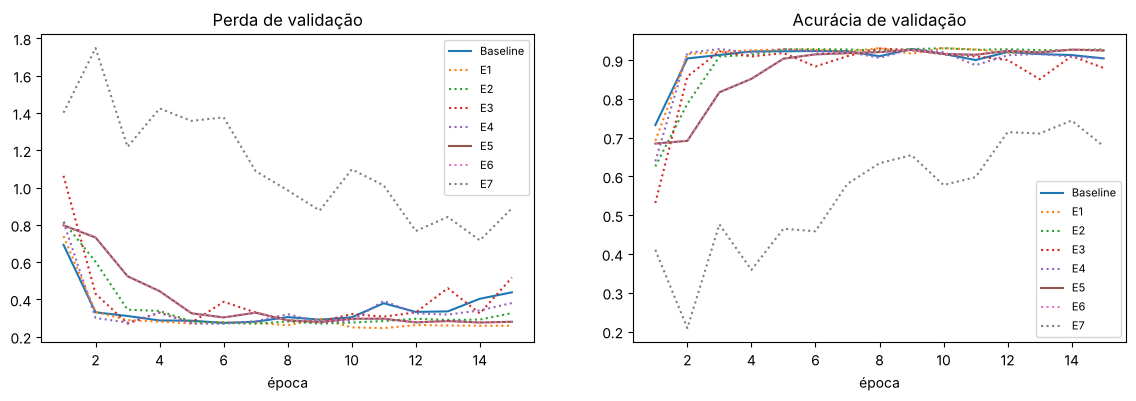

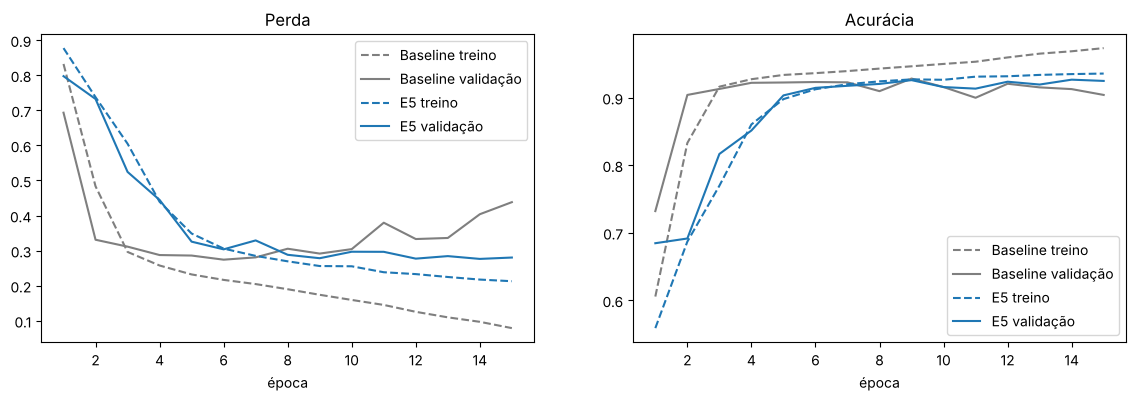

In [ ]:
curvas(hist_A, melhor_A, 'A')

**Interpretação dos experimentos da Parte A** (valores da tabela acima)

**1. Qual fator mais subiu o F1 macro? A acurácia acompanhou?**
Só um experimento melhorou o F1 macro: a **taxa de aprendizado menor (E5, 1e-3 → 3e-4)**, de 52,94% para **55,29%** (+2,36 p.p.). A acurácia de validação acompanhou, subindo de 90,40% para 92,47%.
Nos outros casos, acurácia e F1 macro andaram em **sentidos opostos**. Data augmentation (E1) e dropout (E2) **aumentaram a acurácia** (92,33% e 92,73%), mas **baixaram o F1 macro** (50,97% e 46,43%). Isso mostra que a rede ficou melhor nas classes grandes e pior nas raras, o que a acurácia sozinha esconderia. Por isso escolhemos os modelos pelo F1 macro.

**2. O gap do baseline indica overfitting? Ele caiu com augmentation/dropout?**
Sim. O baseline chegou a **97,90% no treino** contra **90,40% na validação**: gap de **7,50 p.p.**, e a perda de validação sobe a partir da 6ª época. Com data augmentation, o gap caiu para **1,20 p.p.**; com dropout, para **1,85 p.p.** As duas técnicas reduziram o overfitting, como previsto. Mesmo assim, não foram mantidas, porque o critério era o F1 macro, e ele caiu.

**3. Os pesos de classe (E7) ajudaram as classes raras? Com que custo?**
Não. O E7 foi o pior experimento: F1 macro de **40,78%** (−14,51 p.p.) e acurácia de validação de **67,75%**. Até a acurácia de **treino** caiu para 75,94%, sinal de que o **treino ficou instável**. Com pesos "balanced", um erro em *Weird* passou a valer ~25 e um erro em *Uninfected* ~0,4. Os gradientes das poucas imagens raras dominaram o aprendizado, e a rede perdeu desempenho justamente nas classes grandes, que são as clinicamente importantes. Pesos menos extremos, *oversampling* ou *focal loss* seriam alternativas.

**4. Variação aleatória**
Na Parte A, as diferenças entre experimentos passaram de 1 p.p., mas a validação tem só **31 *Weird*, 94 *Unsure* e 96 *Bad segmentation***. Poucas imagens a mais ou a menos acertadas mudam bastante o F1 dessas classes e, portanto, o F1 macro. A escolha do modelo é, por isso, **ruidosa**. Uma validação cruzada por lâmina daria uma estimativa mais confiável.


### 7.1 Avaliação final da Parte A no teste (uso único)

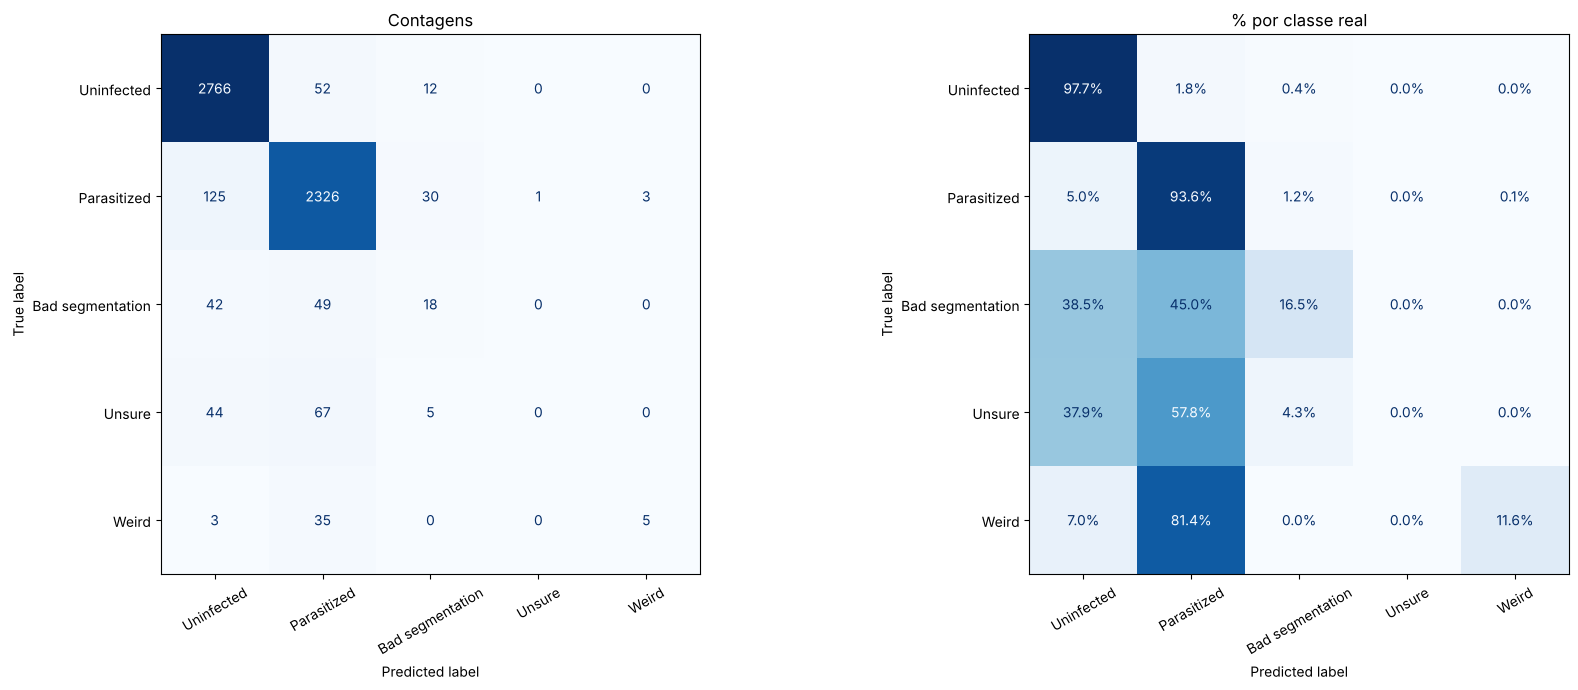

                  precision    recall  f1-score   support

      Uninfected     0.9282    0.9774    0.9522      2830
     Parasitized     0.9197    0.9360    0.9278      2485
Bad segmentation     0.2769    0.1651    0.2069       109
          Unsure     0.0000    0.0000    0.0000       116
           Weird     0.6250    0.1163    0.1961        43

        accuracy                         0.9162      5583
       macro avg     0.5500    0.4390    0.4566      5583
    weighted avg     0.8901    0.9162    0.9012      5583



,precisão,revocação,f1-score,acurácia da classe,suporte
Uninfected,0.9282,0.9774,0.9522,0.9774,2830.0
Parasitized,0.9197,0.9360,0.9278,0.9360,2485.0
Bad segmentation,0.2769,0.1651,0.2069,0.1651,109.0
Unsure,0.0000,0.0000,0.0000,0.0000,116.0
Weird,0.6250,0.1163,0.1961,0.1163,43.0
Acurácia geral,NaN,NaN,NaN,0.9162,5583.0
F1 macro,NaN,NaN,0.4566,NaN,5583.0


In [ ]:
modelo_A = modelos_A[melhor_A]
modelo_A.save('cnn_malaria_5classes.keras')
Xte_A, yte_A = X[idx_test], y5[idx_test]
df_te_A = df.iloc[idx_test].reset_index(drop=True)
prob_A, pred_A, cm_A = avaliar(modelo_A, Xte_A, yte_A, CLASSES5, 'A')

### 7.2 Classes mais confundidas e exemplos

Pares mais confundidos (real → previsto):
  Parasitized       → Uninfected       : 125 imagens
  Unsure            → Parasitized      : 67 imagens
  Uninfected        → Parasitized      : 52 imagens
  Bad segmentation  → Parasitized      : 49 imagens


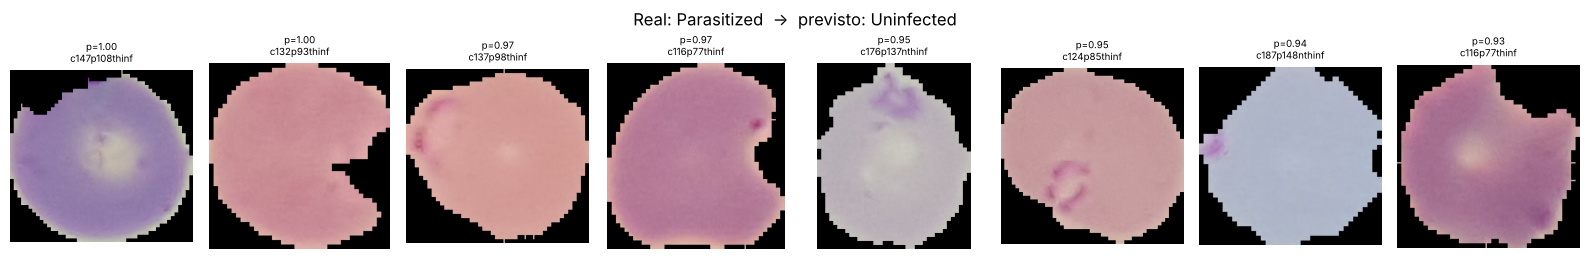

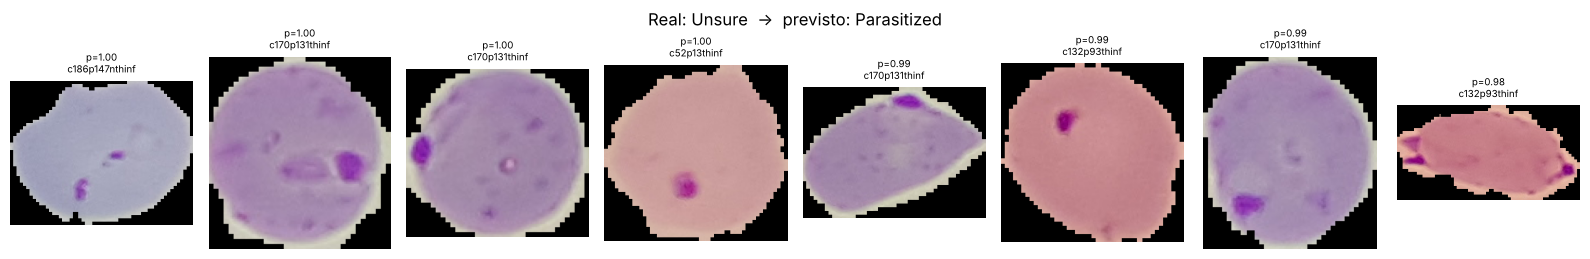

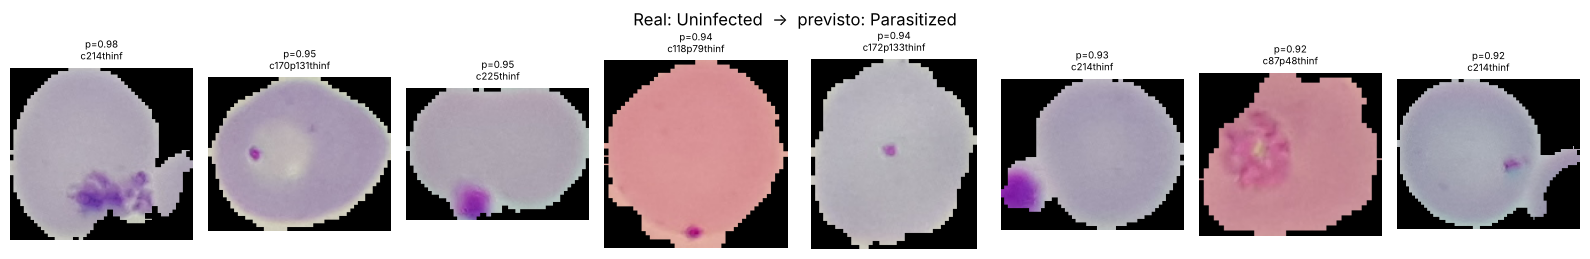

In [ ]:
pares_A = pares_confundidos(cm_A, CLASSES5)
print('Pares mais confundidos (real → previsto):')
for n, r, p in pares_A:
    print(f'  {r:17s} → {p:17s}: {n} imagens')
for k, (n, r, p) in enumerate(pares_A[:3]):
    grade_erros(df_te_A, prob_A, pred_A, yte_A, CLASSES5, r, p, f'A_erros_{k+1}.png')

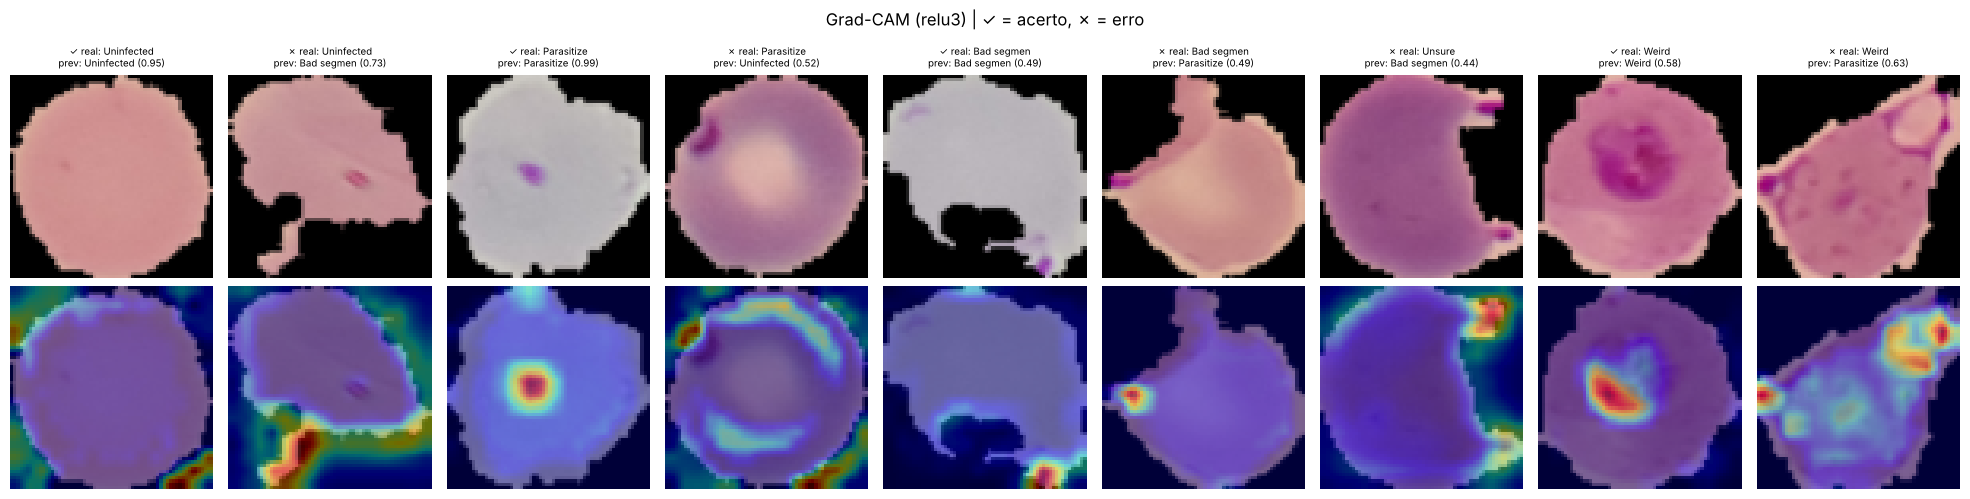

In [ ]:
painel_gradcam(modelo_A, Xte_A, yte_A, pred_A, CLASSES5, 'A_gradcam.png')

## 8. Parte B: 2 classes (*Parasitized* × *Uninfected*)

Mesma rede, mesmos experimentos e **mesma divisão por lâmina**, retirando as imagens *Bad segmentation*, *Unsure* e *Weird* de cada conjunto.

In [ ]:
def so_duas(idx):
    return idx[y5[idx] < 2]          # rótulos 0 (Uninfected) e 1 (Parasitized)
itr_B, iva_B, ite_B = so_duas(idx_train), so_duas(idx_val), so_duas(idx_test)
print('Parte B | treino:', len(itr_B), '| validação:', len(iva_B), '| teste:', len(ite_B))
print('Parasitized (%) | treino {:.1f} | validação {:.1f} | teste {:.1f}'.format(*(100 * y5[i].mean() for i in (itr_B, iva_B, ite_B))))

dados_B = (X[itr_B], y5[itr_B], X[iva_B], y5[iva_B])
tabela_B, modelos_B, hist_B, melhor_B, cfg_B = rodar_experimentos('PARTE B', dados_B, 2)

Parte B | treino: 16812 | validação: 4071 | teste: 5315
Parasitized (%) | treino 45.8 | validação 46.2 | teste 46.8


==================== PARTE B BASELINE ====================


Epoch 1/15


/usr/local/lib/python3.13/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


263/263 - 12s - 47ms/step - accuracy: 0.7316 - loss: 0.5009 - val_accuracy: 0.9649 - val_loss: 0.2059


Epoch 2/15


... (248 outputs left out)

263/263 - 21s - 78ms/step - accuracy: 0.9809 - loss: 0.0637 - val_accuracy: 0.9803 - val_loss: 0.0679


Epoch 15/15


263/263 - 20s - 76ms/step - accuracy: 0.9811 - loss: 0.0597 - val_accuracy: 0.9796 - val_loss: 0.0694



PARTE B: modelo escolhido = E5 | config = {'aug': True, 'dropout': 0.0, 'bn': False, 'blocos': 4, 'lr': 0.0003, 'early_stopping': False, 'pesos_classe': False}


In [ ]:
mostrar_tabela(tabela_B, 'B_tabela_experimentos.csv')

,exp,fator,hipotese,params,épocas,acc treino %,acc val %,F1 macro val %,gap (p.p.),tempo (s),resultado,conclusao
0,Baseline,—,Referência.,285922,15,99.73,97.37,97.36,2.35,228,—,Ponto de partida.
1,E1,Data augmentation,Células não têm orientação fixa; girar/espelha...,285922,15,98.08,97.84,97.83,0.24,262,melhorou (+0.47 p.p.),Mantido.
2,E2,"Dropout 0,5",A Dense concentra ~92% dos parâmetros; desliga...,285922,15,98.17,97.81,97.80,0.36,264,não melhorou (-0.02 p.p.),Descartado.
3,E3,Batch Normalization,Normalizar as ativações estabiliza o treino e ...,286258,15,97.91,97.32,97.31,0.58,483,não melhorou (-0.52 p.p.),Descartado.
4,E4,+1 bloco conv (128 filtros),Mais um bloco aprende padrões mais complexos e...,228706,15,98.32,97.99,97.97,0.34,287,melhorou (+0.15 p.p.),Mantido.
5,E5,Taxa de aprendizado 1e-3 → 3e-4,Passos menores deixam a validação mais estável.,228706,15,98.26,98.08,98.07,0.17,286,melhorou (+0.10 p.p.),Mantido.
6,E6,Early stopping (paciência 4),Parar quando a validação deixa de melhorar evi...,228706,15,98.23,97.91,97.90,0.32,287,não melhorou (-0.17 p.p.),Descartado.
7,E7,Pesos de classe (balanced),Dar mais peso aos erros das classes raras aume...,228706,15,98.26,97.96,97.95,0.30,298,não melhorou (-0.12 p.p.),Descartado.


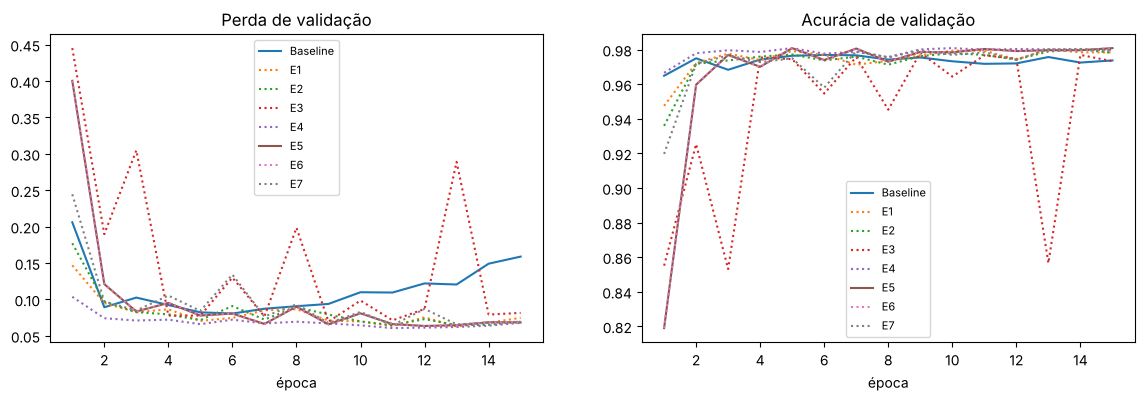

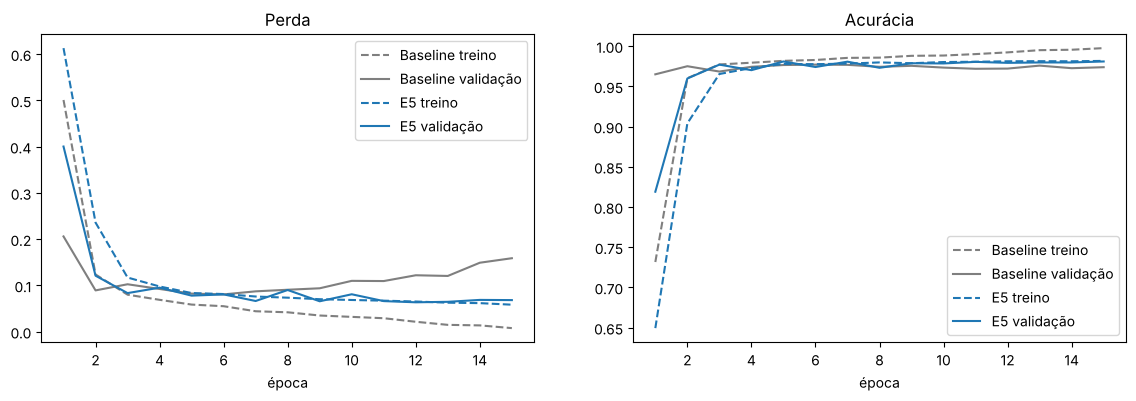

In [ ]:
curvas(hist_B, melhor_B, 'B')

### 8.1 Avaliação final da Parte B no teste (uso único)

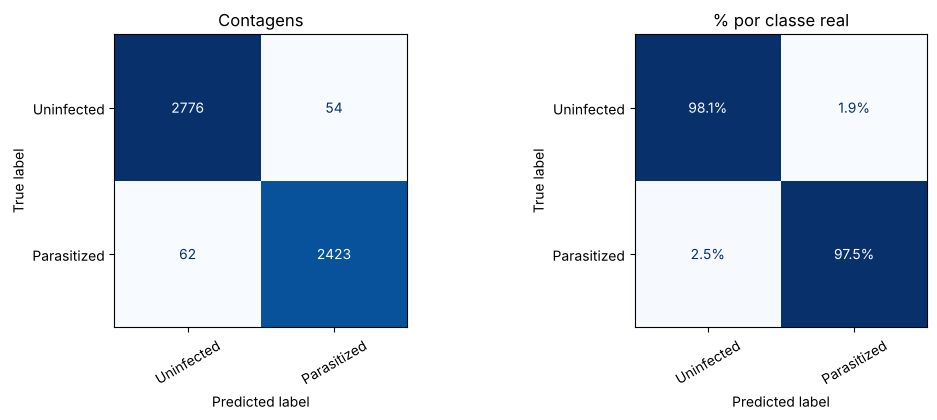

              precision    recall  f1-score   support

  Uninfected     0.9782    0.9809    0.9795      2830
 Parasitized     0.9782    0.9751    0.9766      2485

    accuracy                         0.9782      5315
   macro avg     0.9782    0.9780    0.9781      5315
weighted avg     0.9782    0.9782    0.9782      5315



,precisão,revocação,f1-score,acurácia da classe,suporte
Uninfected,0.9782,0.9809,0.9795,0.9809,2830.0
Parasitized,0.9782,0.9751,0.9766,0.9751,2485.0
Acurácia geral,NaN,NaN,NaN,0.9782,5315.0
F1 macro,NaN,NaN,0.9781,NaN,5315.0


VN=2776  FP=54  FN=62  VP=2423  | falsos negativos = infecções não detectadas


In [ ]:
modelo_B = modelos_B[melhor_B]
modelo_B.save('cnn_malaria_2classes.keras')
Xte_B, yte_B = X[ite_B], y5[ite_B]
df_te_B = df.iloc[ite_B].reset_index(drop=True)
prob_B, pred_B, cm_B = avaliar(modelo_B, Xte_B, yte_B, CLASSES2, 'B')
tn, fp, fn, tp = cm_B.ravel()
print(f'VN={tn}  FP={fp}  FN={fn}  VP={tp}  | falsos negativos = infecções não detectadas')

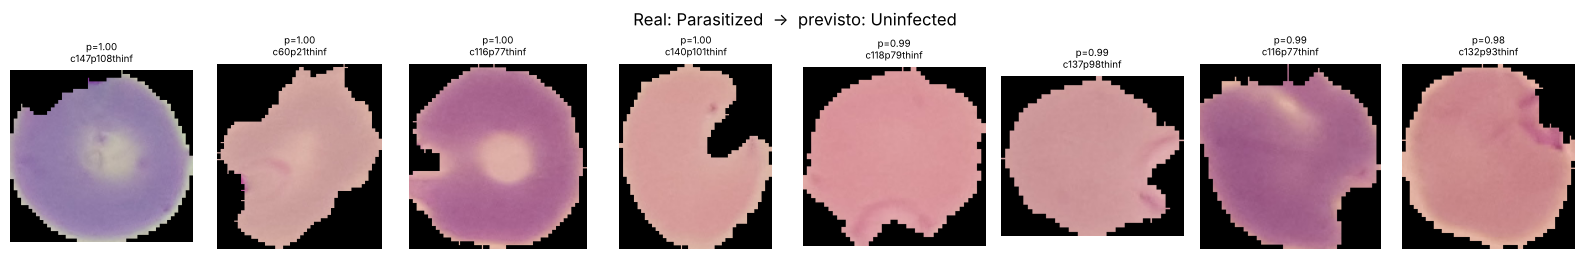

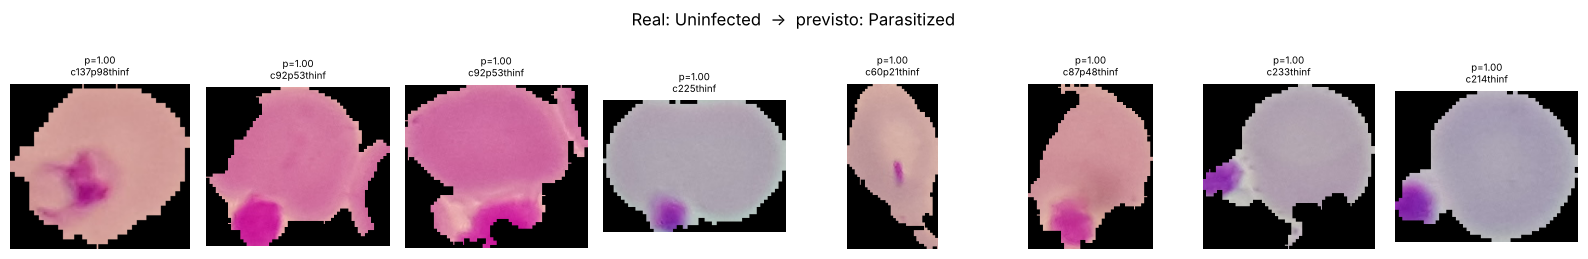

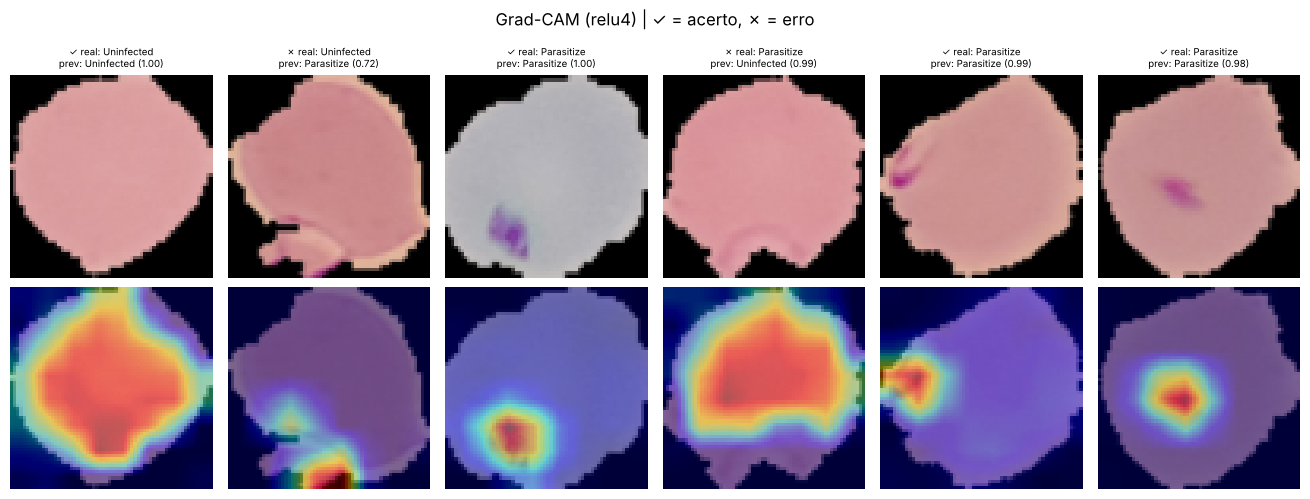

In [ ]:
grade_erros(df_te_B, prob_B, pred_B, yte_B, CLASSES2, 'Parasitized', 'Uninfected', 'B_erros_falsos_negativos.png')
grade_erros(df_te_B, prob_B, pred_B, yte_B, CLASSES2, 'Uninfected', 'Parasitized', 'B_erros_falsos_positivos.png')
painel_gradcam(modelo_B, Xte_B, yte_B, pred_B, CLASSES2, 'B_gradcam.png')

## 9. Parte C: comparação 5 classes × 2 classes

### 🔧 Como comparar de forma justa
Os dois modelos resolvem problemas diferentes, então comparamos de três jeitos:
1. **Métricas de cada um no seu próprio teste** (acurácia e F1 macro).
2. **No mesmo conjunto de imagens:** só as imagens *Parasitized* e *Uninfected* do teste, que são **exatamente** o teste da Parte B. O modelo de 5 classes pode mandar algumas delas para *Bad segmentation/Unsure/Weird*; mostramos quantas.
3. **Juntando as previsões do modelo de 5 classes em 2:** consideramos *Parasitized* só o que ele previu como *Parasitized*, e todo o resto como "não parasitado".

In [ ]:
mask = yte_A < 2                                  # imagens P/U do teste da Parte A = teste da Parte B
assert mask.sum() == len(yte_B)
pA = pred_A[mask]; yPU = yte_A[mask]

# (2) para onde o modelo de 5 classes mandou as imagens P/U
destino = pd.crosstab(pd.Series(yPU).map(dict(enumerate(CLASSES5))).rename('real'),
                      pd.Series(pA).map(dict(enumerate(CLASSES5))).rename('previsto pelo modelo de 5 classes')
                      ).reindex(index=CLASSES2, columns=CLASSES5, fill_value=0)
display(destino)

# (3) modelo de 5 classes "colapsado" em 2: Parasitized x resto
pA_bin = (pA == 1).astype(int)
def resumo(y, p):
    rep = classification_report(y, p, output_dict=True, zero_division=0)
    return {'acurácia': accuracy_score(y, p), 'F1 macro': f1_score(y, p, average='macro'),
            'sensibilidade (recall Parasitized)': rep['1']['recall'], 'precisão Parasitized': rep['1']['precision'],
            'especificidade (recall Uninfected)': rep['0']['recall']}
comp = pd.DataFrame({
    'A: 5 classes (teste completo)': {'acurácia': accuracy_score(yte_A, pred_A), 'F1 macro': f1_score(yte_A, pred_A, average='macro')},
    'A: 5 classes (só imagens P/U, colapsado)': resumo(yPU, pA_bin),
    'B: 2 classes (teste P/U)': resumo(yte_B, pred_B),
}).T
comp.loc['A: 5 classes (só imagens P/U, colapsado)', 'imagens P/U enviadas às classes novas'] = int((pA >= 2).sum())
comp.round(4).to_csv(os.path.join(FIG_DIR, 'C_comparacao.csv'))
(comp * 1).round(4)

previsto pelo modelo de 5 classes,Uninfected,Parasitized,Bad segmentation,Unsure,Weird
real,,,,,
Uninfected,2766,52,12,0,0
Parasitized,125,2326,30,1,3


,acurácia,F1 macro,sensibilidade (recall Parasitized),precisão Parasitized,especificidade (recall Uninfected),imagens P/U enviadas às classes novas
A: 5 classes (teste completo),0.9162,0.4566,NaN,NaN,NaN,NaN
"A: 5 classes (só imagens P/U, colapsado)",0.9603,0.9600,0.9360,0.9781,0.9816,46.0
B: 2 classes (teste P/U),0.9782,0.9781,0.9751,0.9782,0.9809,NaN


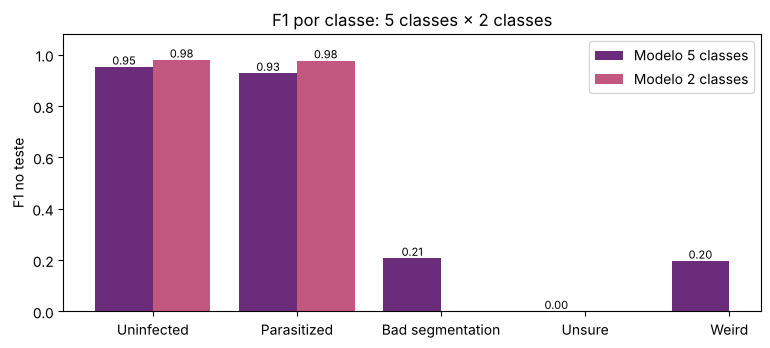

In [ ]:
# F1 por classe dos dois modelos, lado a lado
f1A = f1_score(yte_A, pred_A, average=None, labels=range(5))
f1B = f1_score(yte_B, pred_B, average=None, labels=range(2))
fig, ax = plt.subplots(figsize=(9, 3.6))
x = np.arange(5)
ax.bar(x - 0.2, f1A, 0.4, label='Modelo 5 classes', color='#6B2D7B')
ax.bar(x[:2] + 0.2, f1B, 0.4, label='Modelo 2 classes', color='#C2577F')
for xi, v in zip(x - 0.2, f1A): ax.text(xi, v + 0.01, f'{v:.2f}', ha='center', fontsize=8)
for xi, v in zip(x[:2] + 0.2, f1B): ax.text(xi, v + 0.01, f'{v:.2f}', ha='center', fontsize=8)
ax.set_xticks(x); ax.set_xticklabels(CLASSES5); ax.set_ylim(0, 1.08); ax.set_ylabel('F1 no teste'); ax.legend()
ax.set_title('F1 por classe: 5 classes × 2 classes')
salvar('C_f1_por_classe.png'); plt.show()

### 9.1 Comparação com transfer learning (somente referência)
Uma **MobileNetV2** pré-treinada no ImageNet e **congelada**, com uma cabeça nova, avaliada **na validação** de cada parte (o teste fica reservado aos modelos do grupo).

In [ ]:
if RODAR_TRANSFER:
    def transfer(dados, n_classes):
        Xtr, ytr, Xva, yva = dados
        keras.utils.set_random_seed(SEED)
        base = keras.applications.MobileNetV2(include_top=False, weights='imagenet', input_shape=(96, 96, 3))
        base.trainable = False                                         # pesos pré-treinados congelados
        m = keras.Sequential([keras.Input(shape=(IMG_SIZE, IMG_SIZE, 3)), layers.Resizing(96, 96),
                              layers.Rescaling(1. / 127.5, offset=-1), base, layers.GlobalAveragePooling2D(),
                              layers.Dropout(0.2), layers.Dense(n_classes, activation='softmax')])
        m.compile(optimizer=keras.optimizers.Adam(1e-3), loss='sparse_categorical_crossentropy', metrics=['accuracy'])
        m.fit(ds(Xtr, ytr, True), validation_data=ds(Xva, yva), epochs=5, verbose=2)
        pv = m.predict(Xva, batch_size=256, verbose=0).argmax(1)
        return accuracy_score(yva, pv), f1_score(yva, pv, average='macro')
    linhas = []
    for parte, dados, n, tab, melhor in [('A (5 classes)', dados_A, 5, tabela_A, melhor_A), ('B (2 classes)', dados_B, 2, tabela_B, melhor_B)]:
        acc, f1 = transfer(dados, n)
        nossa = tab.set_index('exp').loc[melhor]
        linhas += [dict(parte=parte, modelo=f'CNN do grupo ({melhor})', acc_val=nossa.acc_val, f1_macro_val=nossa.f1_macro_val),
                   dict(parte=parte, modelo='MobileNetV2 congelada (5 épocas)', acc_val=acc, f1_macro_val=f1)]
    comp_tl = pd.DataFrame(linhas); comp_tl.to_csv(os.path.join(FIG_DIR, 'C_comparacao_transfer.csv'), index=False)
    display(comp_tl.round(4))

**Discussão da comparação** (valores das tabelas acima)

**1. Por que o modelo de 2 classes vai melhor?**
O modelo de 2 classes tem acurácia de **97,82%** e F1 macro de **97,81%**. O de 5 classes tem acurácia de **91,62%**, mas F1 macro de só **45,66%**. A diferença vem das classes raras. *Uninfected* e *Parasitized* vão bem no modelo de 5 classes (F1 de 95,2% e 92,8%), mas *Bad segmentation* (20,7%), *Weird* (19,6%) e principalmente *Unsure* (**0%**, nunca acertada) puxam a média para baixo.

**2. Nas imagens P/U, quantas o modelo de 5 classes mandou para as classes novas? Isso é ruim ou útil?**
Das **5.315** imagens *Parasitized*/*Uninfected* do teste, o modelo de 5 classes mandou **46 (0,9%)** para as classes novas: 34 parasitadas e 12 sadias.
- **Em princípio poderia ser útil:** uma parasitada enviada para "imagem duvidosa" seria revista por uma pessoa, em vez de passar como sadia.
- **Na prática, o modelo de 5 classes não funciona bem como filtro.** Ele quase não reconhece as imagens que realmente são duvidosas: a revocação no teste foi de 16,5% em *Bad segmentation*, 0% em *Unsure* e 11,6% em *Weird*.
- **E ele perde o dobro de infecções:** 125 parasitadas classificadas como *Uninfected*, contra **62** no modelo de 2 classes.
- **Resultado nas imagens P/U:** a sensibilidade fica em **93,60%**, contra **97,51%** no modelo de 2 classes. A especificidade (98,16% × 98,09%) e a precisão de *Parasitized* (97,81% × 97,82%) ficam praticamente iguais.

**3. Quais classes novas mais se confundem com *Parasitized*? Faz sentido?**
Pela matriz de confusão da Parte A, a proporção de cada classe nova prevista como *Parasitized* foi:
- ***Weird*:** 35 de 43 (**81%**);
- ***Unsure*:** 67 de 116 (**58%**);
- ***Bad segmentation*:** 49 de 109 (**45%**).

Faz sentido. Pela comparação com o conjunto original (seção 3.3), quase todas essas imagens estavam rotuladas como *Parasitized* antes da revisão, e muitas têm manchas roxas de verdade. Nos exemplos de *Unsure* previstas como *Parasitized*, os pontos roxos são reais e ambíguos até para o especialista.


## 10. Conclusão

- **Parte A (5 classes):** acurácia de **91,62%**, mas F1 macro de só **45,66%**.
  - As classes grandes vão bem: F1 de 95,2% em *Uninfected* e 92,8% em *Parasitized*.
  - As raras vão mal: *Bad segmentation* 20,7%, *Weird* 19,6% e *Unsure* 0%. São poucas imagens e visualmente parecidas com *Parasitized*; a maioria é prevista como *Parasitized* ou *Uninfected*.
  - Modelo final: baseline com taxa de aprendizado 3e-4 (286.117 parâmetros).
- **Parte B (2 classes):** acurácia de **97,82%**, sensibilidade de **97,51%**, especificidade de **98,09%** e F1 macro de **97,81%**.
  - Foram 62 falsos negativos e 54 falsos positivos em 5.315 imagens.
  - Modelo final: data augmentation + 4º bloco convolucional + taxa de aprendizado 3e-4 (228.706 parâmetros).
  - O overfitting do baseline caiu de um gap de 2,35 p.p. para 0,17 p.p.
- **Comparação:** nas mesmas 5.315 imagens *Parasitized*/*Uninfected*, o modelo de 2 classes tem **3,9 p.p. a mais de sensibilidade** (97,51% × 93,60%) e perde metade das infecções (62 × 125), com especificidade e precisão praticamente iguais. **Para triagem, o modelo de 2 classes é o melhor.** O de 5 classes poderia sinalizar imagens para revisão humana, mas ainda reconhece mal as classes duvidosas.
- **Outros aprendizados:**
  - Com classes desbalanceadas, a **acurácia engana**: na Parte A, augmentation e dropout aumentaram a acurácia, mas reduziram o F1 macro.
  - **Pesos de classe "balanced"** desestabilizaram o treino (acurácia de validação de 67,75%).
  - O **Grad-CAM** mostra que, nos acertos de *Parasitized*, a rede foca o anel do parasita. Vários falsos positivos da Parte B vêm de lâminas de pacientes saudáveis, com manchas roxas fora da hemácia (provavelmente plaquetas ou corante).
- **Limitações:**
  - As classes novas são muito pequenas, e os critérios de "duvidoso" e "estranho" são subjetivos.
  - A validação tem poucas imagens raras, então a escolha pelo F1 macro é ruidosa.
  - As células já vêm recortadas; há uma única espécie (*P. falciparum*) e uma única origem.
  - As imagens foram reduzidas para 64×64, e foi feita uma única divisão treino/validação/teste.
  - A comparação com a MobileNetV2 (seção 9.1) não foi executada nesta versão.
- **Melhorias possíveis:**
  - Mais dados das classes raras; *oversampling* ou *focal loss* em vez de pesos extremos.
  - Validação cruzada por lâmina (os grupos do IEEE já permitem isso).
  - Ajustar o limiar de *Parasitized* para priorizar a sensibilidade, ou usar a confiança do modelo de 2 classes para indicar quando repetir o exame.
  - Imagens maiores, com GPU, e *fine-tuning* de redes pré-treinadas.
- Um modelo assim **apoia** o microscopista na triagem; não o substitui.


In [ ]:
# Empacota figuras e tabelas para os slides
shutil.make_archive('resultados_malaria_ieee', 'zip', FIG_DIR)
print('Arquivos gerados:', sorted(os.listdir(FIG_DIR)))
try:
    from google.colab import files
    files.download('resultados_malaria_ieee.zip')
except Exception:
    print('Fora do Colab: o zip está em resultados_malaria_ieee.zip')

Arquivos gerados: ['A_curvas_baseline_vs_final.png', 'A_curvas_experimentos.png', 'A_erros_1.png', 'A_erros_2.png', 'A_erros_3.png', 'A_gradcam.png', 'A_matriz_confusao.png', 'A_metricas_teste.csv', 'A_tabela_experimentos.csv', 'B_curvas_baseline_vs_final.png', 'B_curvas_experimentos.png', 'B_erros_falsos_negativos.png', 'B_erros_falsos_positivos.png', 'B_gradcam.png', 'B_matriz_confusao.png', 'B_metricas_teste.csv', 'B_tabela_experimentos.csv', 'C_comparacao.csv', 'C_f1_por_classe.png', 'divisao.csv', 'eda_amostras.png', 'eda_distribuicao_classes.png', 'eda_resolucao.png', 'eda_transicao_rotulos.csv']
Fora do Colab: o zip está em resultados_malaria_ieee.zip


## 11. Log de uso de IA generativa

| # | Ferramenta | Prompt (resumo) | O que a IA respondeu/sugeriu | Decisão (aceito / rejeitado / corrigido) e por quê |
|---|---|---|---|---|
| 1 | Claude | Perguntamos a fonte da informação sobre a origem do conjunto | Citou NIH, IEEE DataPort e artigos; admitiu que um detalhe ("recortadas automaticamente") não estava nas fontes e sugeriu corrigir | aceito |
| 2 | Claude | Usar a versão revisada do IEEE para realizar a CNN, 5 classes, depois 2 classes, e comparar |  Executou este notebook com os dados reais e montou um notebook |aceito |
| 3 | Claude | Crie um video para ajudar a compreender a teoria e o projeto | Cirada um video com todas as informações do projeto | aceito |
| 4 | Claude | Enviamos o enunciado e o material da aula e perguntamos se era preciso baixar o dataset para a IA | Disse que o download deve ser feito no Colab, porque os números precisam vir da execução real do notebook | _(preencher)_ |
| 5 | Claude | Pedimos: redimensionar as imagens, baseline + experimentos (augmentation, dropout), tabela de resultados e PPT | Gerou o 1º notebook (2 classes, dados originais do Kaggle) e um PPT | _(preencher)_ |
| 6 | Claude | Perguntamos se a IA tinha criado dados novos | Explicou o que foi gerado (imagens sintéticas só para testar o código, augmentation em memória) e que nenhum número foi inventado | _(preencher)_ |
| 7 | Claude | Pedimos mais explicações teóricas e uma seção sobre malária | Acrescentou teoria em cada etapa, comentários no código e o contexto da malária | _(preencher)_ |
| 8 | Claude | Avisamos que a pasta duplicada do Kaggle tinha sido removida manualmente | Reconheceu a conclusão errada e corrigiu o texto e o log | _(preencher)_ |
| 9 | Claude | Perguntamos: e se juntarmos as 3 classes novas numa só ("repetir exame")? | Testou com 3 classes; a classe "repetir exame" teve revocação de só 15,7% e o modelo de 2 classes continuou melhor | _(preencher)_ |
| 10 | Claude | Pedimos para terminar a conclusão e responder às questões do notebook | Preencheu a interpretação dos experimentos, a discussão da comparação e a conclusão com os números da execução | _(preencher)_ |

### Correções críticas (mínimo 2)
| # | O que a IA errou ou sugeriu de inadequado | Como foi percebido | Como foi corrigido |
|---|---|---|---|
| 1 | Ao ver "27.558 encontrados → 27.558 únicos", a IA concluiu que a afirmação "o zip do Kaggle vem com a pasta duplicada" estava errada e registrou isso como erro dela | A integrante que preparou os dados percebeu ao ler o log: ela tinha apagado a pasta repetida manualmente antes de enviar o zip | Texto original restaurado; o código de deduplicação foi mantido |
| 2 | No 1º notebook, a hipótese do early stopping dizia que ele **pararia** o treino antes do overfitting; ele nunca parou | Comparando a saída (todas as épocas executadas) com o código do Keras: `restore_best_weights` restaura a melhor época mesmo sem parar o treino | Interpretação corrigida: o ganho veio da restauração dos pesos, não da parada antecipada |
| 3 | A IA afirmou que as células foram "recortadas automaticamente", informação que não estava nas fontes consultadas | O grupo pediu a fonte do parágrafo | Texto ajustado para não afirmar o que não foi verificado |
| 4 | O texto dizia que o mapa do Grad-CAM era 8×8 ou 4×4; na verdade é 16×16 (3 blocos) ou 8×8 (4 blocos), porque o Grad-CAM usa a saída da ReLU **antes** do último pooling | Percebido ao calcular o Grad-CAM para o vídeo didático (o mapa saiu com 8×8 no modelo de 4 blocos) | Texto da seção 6 corrigido |
| 5 | A IA sugeriu pesos de classe "balanced" (E7) para ajudar as classes raras | O E7 foi o pior experimento: a acurácia de validação caiu para 67,75% e a de treino para 75,94% (treino instável) | Hipótese descartada; registramos como alternativas *oversampling*, *focal loss* ou pesos menos extremos |

